# WindGuard

**Pipeline:** Zenodo API data retrieval → Member 1 EDA → data preparation and chronological split → Member 2 feature engineering and PCA/anomaly detection → Member 3 Logistic Regression, SVM and Bayesian classification.


## 1. Retrieve the dataset through the Zenodo API

In [46]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [1]:
import io
import os
import zipfile
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from tqdm.notebook import tqdm

warnings.filterwarnings("ignore")

ZENODO_RECORD_ID = "16807551"
API_URL = f"https://zenodo.org/api/records/{ZENODO_RECORD_ID}"
HEADERS = {"User-Agent": "WindGuard-Research-Notebook/1.0"}

response = requests.get(API_URL, headers=HEADERS, timeout=60)
response.raise_for_status()
record = response.json()
file_lookup = {item["key"]: item for item in record.get("files", [])}

In [2]:
required_archive = "Kelmarsh_SCADA_2019_3085.zip"
if required_archive not in file_lookup:
    raise FileNotFoundError(
        f"{required_archive} was not listed in Zenodo record {ZENODO_RECORD_ID}. "
        f"Available files: {list(file_lookup)}"
    )

# Fetch the archive into RAM; no raw dataset file is written to Drive or disk.
archive_info = file_lookup[required_archive]
archive_url = archive_info["links"].get("content", archive_info["links"]["self"])
print(f"Retrieving {required_archive} ({archive_info['size'] / 1024**2:.1f} MB) into Colab memory.")

with requests.get(archive_url, headers=HEADERS, stream=True, timeout=(30, 600)) as r:
    r.raise_for_status()
    chunks = []
    total = int(r.headers.get("content-length", archive_info["size"]))
    with tqdm(total=total, unit="B", unit_scale=True, desc="Zenodo API") as bar:
        for chunk in r.iter_content(chunk_size=4 * 1024 * 1024):
            if chunk:
                chunks.append(chunk)
                bar.update(len(chunk))

archive_bytes = b"".join(chunks)
zip_buffer = io.BytesIO(archive_bytes)

Retrieving Kelmarsh_SCADA_2019_3085.zip (296.9 MB) into Colab memory.


Zenodo API:   0%|          | 0.00/311M [00:00<?, ?B/s]

In [3]:
# Find the required turbine SCADA and status CSVs inside the ZIP.
with zipfile.ZipFile(zip_buffer) as zf:
    members = zf.namelist()
    scada_matches = [n for n in members if os.path.basename(n) == "Turbine_Data_Kelmarsh_1_2019-01-01_-_2020-01-01_228.csv"]
    status_matches = [n for n in members if os.path.basename(n) == "Status_Kelmarsh_1_2019-01-01_-_2020-01-01_228.csv"]

    if not scada_matches:
        raise FileNotFoundError("Turbine 1 SCADA CSV was not found inside the Zenodo archive.")
    if not status_matches:
        raise FileNotFoundError("Turbine 1 status CSV was not found inside the Zenodo archive.")

    scada_member = scada_matches[0]
    status_member = status_matches[0]

    # Parse directly from in-memory ZIP members.
    with zf.open(scada_member) as f:
        df_t1 = pd.read_csv(f, skiprows=9, low_memory=False)
    df_t1.columns = [str(c).replace("# ", "").strip() for c in df_t1.columns]

    with zf.open(status_member) as f:
        df_status = pd.read_csv(f, comment="#", skipinitialspace=True)

In [4]:
# Prepare timestamps and numeric SCADA values.
if "Date and time" not in df_t1.columns:
    raise KeyError("Expected SCADA timestamp column 'Date and time' was not found.")

df_t1["Date and time"] = pd.to_datetime(df_t1["Date and time"], errors="coerce")
df_t1 = (df_t1.dropna(subset=["Date and time"])
              .sort_values("Date and time")
              .drop_duplicates("Date and time")
              .reset_index(drop=True))

print("SCADA shape:", df_t1.shape)
print("Status shape:", df_status.shape)
print("SCADA member:", scada_member)
print("Status member:", status_member)
print("Archive is held in RAM only; no Drive mount or raw-file save was performed.")

SCADA shape: (52560, 299)
Status shape: (7821, 9)
SCADA member: Turbine_Data_Kelmarsh_1_2019-01-01_-_2020-01-01_228.csv
Status member: Status_Kelmarsh_1_2019-01-01_-_2020-01-01_228.csv
Archive is held in RAM only; no Drive mount or raw-file save was performed.


## 2. Member 1 — Exploratory data analysis

**Plot-rendering correction:** Multi-panel figures are kept in a single code cell from `plt.subplots()` through `plt.show()`. This prevents Colab/Jupyter from displaying a half-built figure between cells, which previously left several panels blank.


### 2.1 Inspect key SCADA variables and missing values

,count,mean,std,min,25%,50%,75%,max
Wind speed (m/s),52476.0,6.072696,2.708171,0.134232,4.140000,5.850106,7.596334,22.266128
Power (kW),52476.0,604.466215,603.401798,-17.846463,123.221998,392.919008,910.904900,2081.028912
Gear oil temperature (°C),50132.0,53.416299,5.356089,13.850000,51.136875,54.450001,57.182499,60.110001
Front bearing temperature (°C),50132.0,66.799149,9.525749,14.040000,63.990002,70.897500,72.944999,79.855000
Nacelle ambient temperature (°C),50132.0,11.673565,5.727920,-0.205000,7.245000,10.958947,15.695000,36.720000
Rotor speed (RPM),52476.0,10.450541,3.993933,0.000000,8.289167,10.741135,13.800764,15.326198
Generator RPM (RPM),52476.0,1239.955158,472.255819,-151.968155,985.464204,1275.014185,1635.408613,1814.115664


,missing_pct
Wind speed (m/s),0.159817
Power (kW),0.159817
Gear oil temperature (°C),4.619482
Front bearing temperature (°C),4.619482
Nacelle ambient temperature (°C),4.619482
Rotor speed (RPM),0.159817
Generator RPM (RPM),0.159817


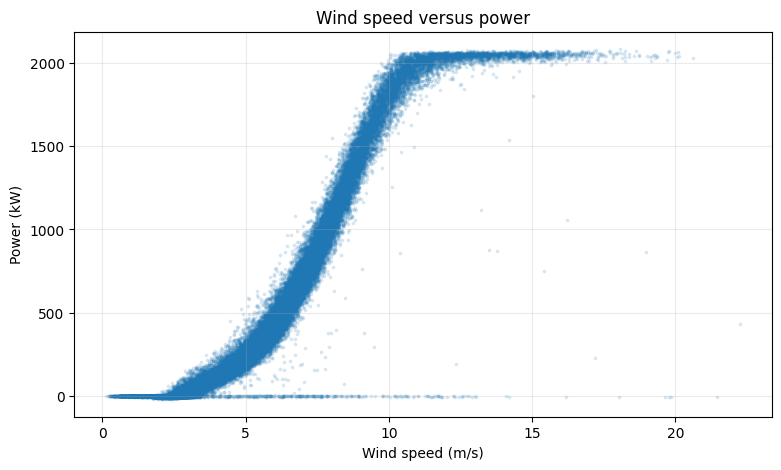

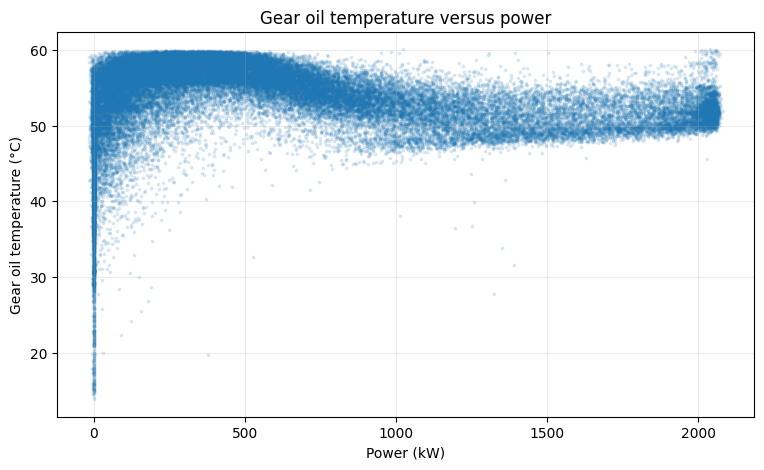

In [5]:
# Inspect core operating variables and data quality.
core_cols = [c for c in [
    "Wind speed (m/s)", "Power (kW)", "Gear oil temperature (°C)",
    "Front bearing temperature (°C)", "Nacelle ambient temperature (°C)",
    "Rotor speed (RPM)", "Generator RPM (RPM)"
] if c in df_t1.columns]

display(df_t1[core_cols].describe().T)
display((df_t1[core_cols].isna().mean() * 100).rename("missing_pct").to_frame())

if {"Wind speed (m/s)", "Power (kW)"}.issubset(df_t1.columns):
    plt.figure(figsize=(9, 5))
    plt.scatter(df_t1["Wind speed (m/s)"], df_t1["Power (kW)"], s=3, alpha=0.12)
    plt.xlabel("Wind speed (m/s)")
    plt.ylabel("Power (kW)")
    plt.title("Wind speed versus power")
    plt.grid(alpha=0.25)
    plt.show()

if {"Power (kW)", "Gear oil temperature (°C)"}.issubset(df_t1.columns):
    plt.figure(figsize=(9, 5))
    plt.scatter(df_t1["Power (kW)"], df_t1["Gear oil temperature (°C)"], s=3, alpha=0.12)
    plt.xlabel("Power (kW)")
    plt.ylabel("Gear oil temperature (°C)")
    plt.title("Gear oil temperature versus power")
    plt.grid(alpha=0.25)
    plt.show()

### 2.2 Wind speed and power relationship

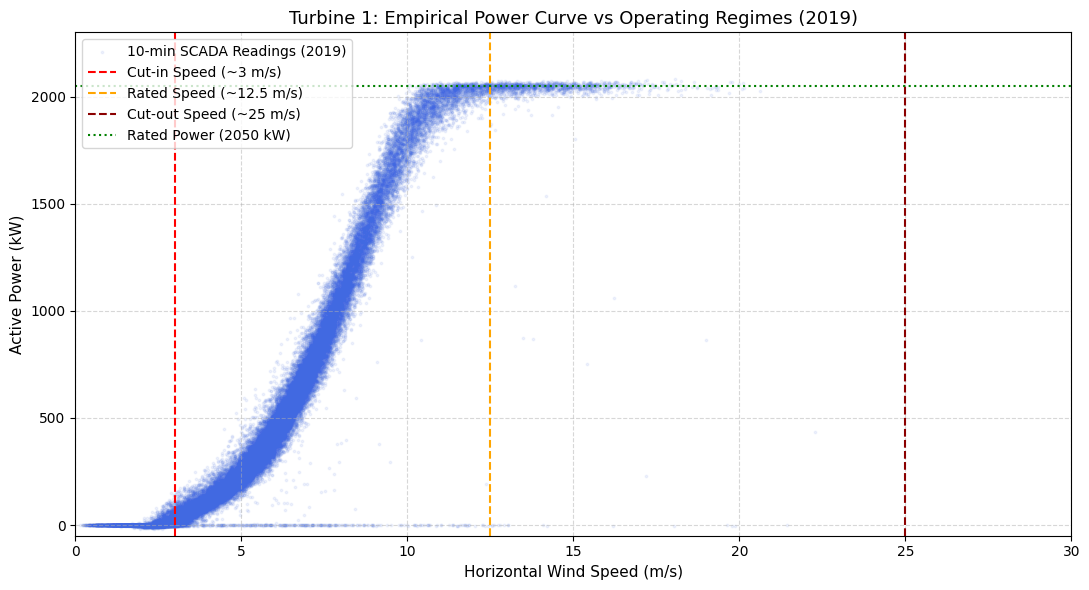

In [6]:
import matplotlib.pyplot as plt

# 1. Relevant columns pick karein
wind_col = 'Wind speed (m/s)'
power_col = 'Power (kW)'

# 2. Numeric conversion ensure karein
df_t1[wind_col] = pd.to_numeric(df_t1[wind_col], errors='coerce')
df_t1[power_col] = pd.to_numeric(df_t1[power_col], errors='coerce')

# 3. Power Curve plot karein
plt.figure(figsize=(11, 6))

# SCADA observations scatter
plt.scatter(
    df_t1[wind_col],
    df_t1[power_col],
    alpha=0.08,
    s=3,
    c='royalblue',
    label='10-min SCADA Readings (2019)'
)

# Senvion MM92 operational reference lines
plt.axvline(3.0, color='red', linestyle='--', linewidth=1.5, label='Cut-in Speed (~3 m/s)')
plt.axvline(12.5, color='orange', linestyle='--', linewidth=1.5, label='Rated Speed (~12.5 m/s)')
plt.axvline(25.0, color='darkred', linestyle='--', linewidth=1.5, label='Cut-out Speed (~25 m/s)')
plt.axhline(2050, color='green', linestyle=':', linewidth=1.5, label='Rated Power (2050 kW)')

plt.title('Turbine 1: Empirical Power Curve vs Operating Regimes (2019)', fontsize=13)
plt.xlabel('Horizontal Wind Speed (m/s)', fontsize=11)
plt.ylabel('Active Power (kW)', fontsize=11)
plt.xlim(0, 30)
plt.ylim(-50, 2300)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


### 2.3 Thermal behaviour

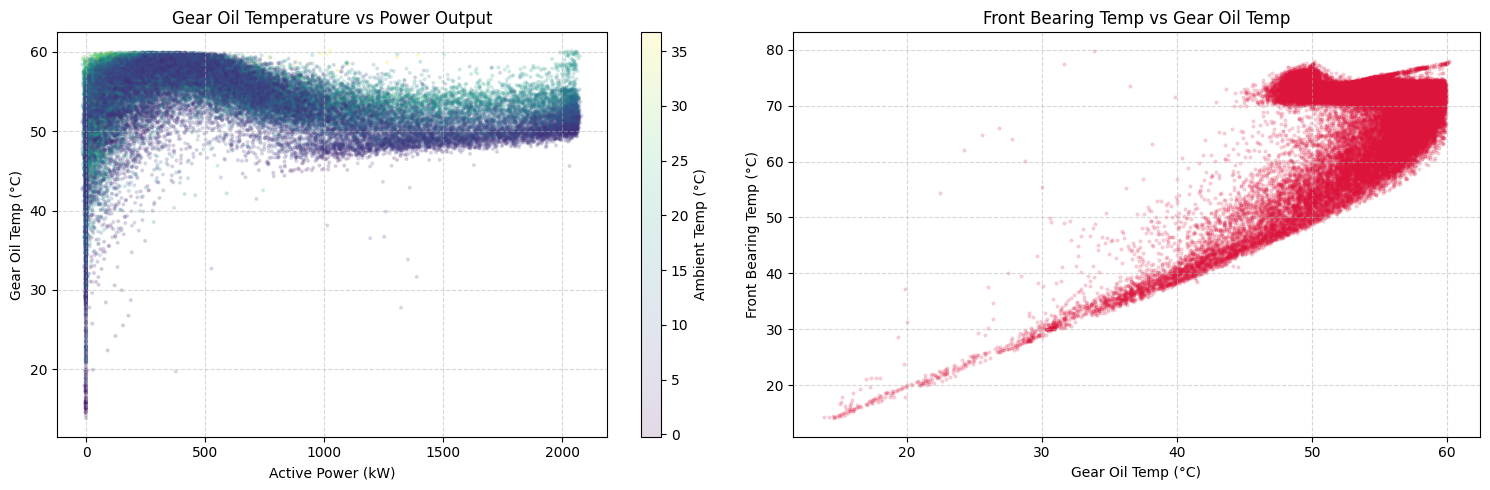

In [7]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Thermal aur ambient columns pick karein
gear_temp_col = 'Gear oil temperature (°C)'
bearing_temp_col = 'Front bearing temperature (°C)'
ambient_temp_col = 'Nacelle ambient temperature (°C)'
power_col = 'Power (kW)'

# Numeric clean
for c in [gear_temp_col, bearing_temp_col, ambient_temp_col]:
    df_t1[c] = pd.to_numeric(df_t1[c], errors='coerce')

# 2. Temperature vs Power Relationship Plot
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot A: Gear Oil Temp vs Active Power
scatter1 = axes[0].scatter(
    df_t1[power_col],
    df_t1[gear_temp_col],
    c=df_t1[ambient_temp_col],
    cmap='viridis',
    alpha=0.15,
    s=4
)
axes[0].set_title('Gear Oil Temperature vs Power Output')
axes[0].set_xlabel('Active Power (kW)')
axes[0].set_ylabel('Gear Oil Temp (°C)')

axes[0].grid(True, linestyle='--', alpha=0.5)
cbar1 = plt.colorbar(scatter1, ax=axes[0])
cbar1.set_label('Ambient Temp (°C)')

# Plot B: Bearing Temp vs Gear Oil Temp (Coupling check)
scatter2 = axes[1].scatter(
    df_t1[gear_temp_col],
    df_t1[bearing_temp_col],
    alpha=0.15,
    s=4,
    c='crimson'
)
axes[1].set_title('Front Bearing Temp vs Gear Oil Temp')
axes[1].set_xlabel('Gear Oil Temp (°C)')
axes[1].set_ylabel('Front Bearing Temp (°C)')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### 2.4 Operating-regime exploration with K-Means

In [8]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# 1. Clustering ke liye features pick karein
features = ['Wind speed (m/s)', 'Power (kW)']
cluster_df = df_t1[features].dropna().copy()

# 2. Features ko scale karein (Z-score normalization)
# Wind speed (0-25) aur Power (0-2050) ke scales alag hain, isliye scaling zaroori hai
scaler = StandardScaler()
scaled_features = scaler.fit_transform(cluster_df)

# 3. K-Means algorithm run karein (k=3 regimes)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_df['Regime'] = kmeans.fit_predict(scaled_features)

# 4. Result ko visualize karein
plt.figure(figsize=(10, 6))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

<Figure size 1000x600 with 0 Axes>

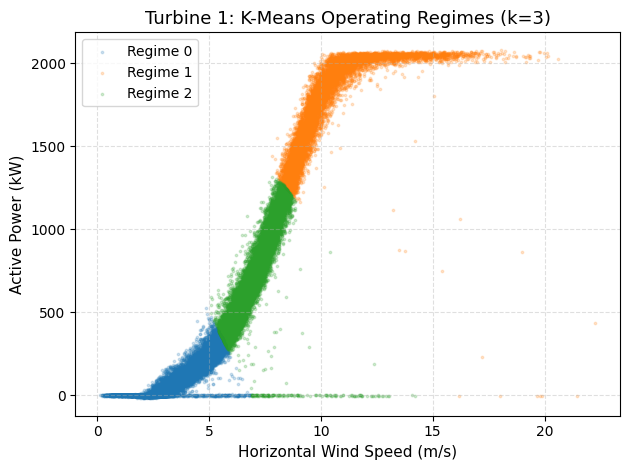


--- Regimes Summary Statistics ---


Wind speed (m/s)               Power (kW)                         
                    min   mean    max        min     mean      max  count
Regime                                                                   
0                  0.13   3.83   6.87     -17.85   126.88   523.57  24209
1                  7.79  10.44  22.27      -3.65  1728.71  2081.03   8863
2                  5.08   6.87  14.20      -6.23   686.80  1314.73  19404

In [9]:
for cluster_id, color in zip(sorted(cluster_df['Regime'].unique()), colors):
    subset = cluster_df[cluster_df['Regime'] == cluster_id]
    plt.scatter(
        subset['Wind speed (m/s)'],
        subset['Power (kW)'],
        s=3,
        alpha=0.2,
        c=color,
        label=f'Regime {cluster_id}'
    )

plt.title('Turbine 1: K-Means Operating Regimes (k=3)', fontsize=13)
plt.xlabel('Horizontal Wind Speed (m/s)', fontsize=11)
plt.ylabel('Active Power (kW)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

# Har regime ka summary stats dekhein
print("\n--- Regimes Summary Statistics ---")
summary = cluster_df.groupby('Regime').agg({
    'Wind speed (m/s)': ['min', 'mean', 'max'],
    'Power (kW)': ['min', 'mean', 'max', 'count']
}).round(2)
display(summary)

### 2.5 Hydraulic-pressure event inspection

Found Hydraulic Fault Events:


,Timestamp start,Timestamp end,Message,Status
527,2019-02-24 02:31:49,2019-02-24 02:39:36,Low hydraulic pressure,Stop
1056,2019-03-27 20:32:14,2019-03-27 20:40:36,Low hydraulic pressure,Stop



Analyzing precursor window around: 2019-02-24 02:31:49


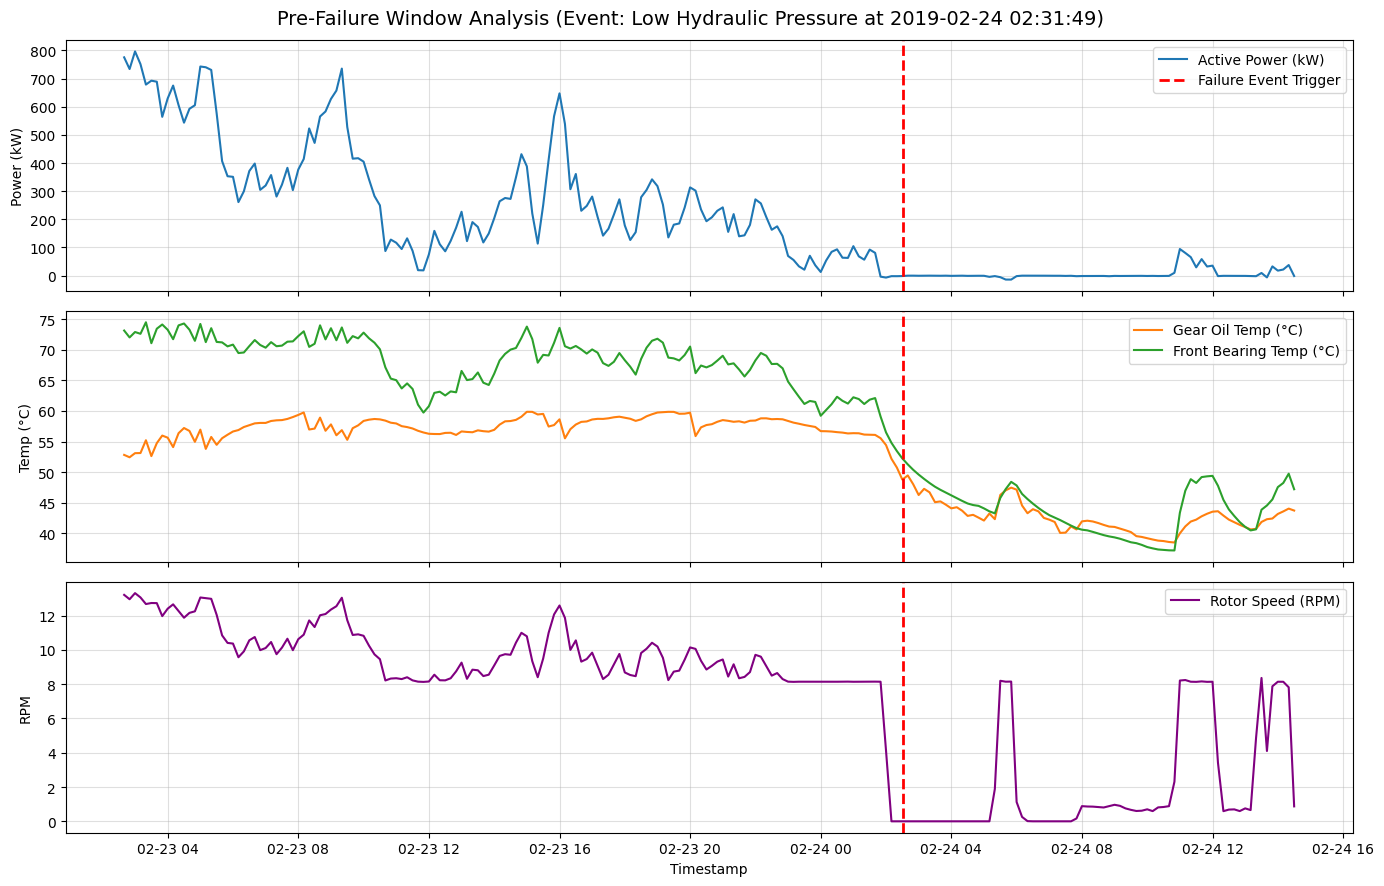

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Status log se hydraulic pressure failure ka exact timestamp nikalte hain
fault_events = df_status[df_status['Message'].str.contains('hydraulic pressure', case=False, na=False)]
print("Found Hydraulic Fault Events:")
display(fault_events[['Timestamp start', 'Timestamp end', 'Message', 'Status']])

# 2. Pehla fault timestamp pick karte hain
target_time = pd.to_datetime(fault_events.iloc[0]['Timestamp start'])
print(f"\nAnalyzing precursor window around: {target_time}")

# 3. Fault se 24 ghante pehle aur 12 ghante baad ka SCADA slice cut karein
start_window = target_time - pd.Timedelta(hours=24)
end_window = target_time + pd.Timedelta(hours=12)

scada_window = df_t1[(df_t1['Date and time'] >= start_window) & (df_t1['Date and time'] <= end_window)].copy()

# 4. Multi-sensor Precursor Trend Plot karein
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)

# Graph 1: Power vs Wind
axes[0].plot(scada_window['Date and time'], scada_window['Power (kW)'], color='tab:blue', label='Active Power (kW)')
axes[0].set_ylabel('Power (kW)')
axes[0].axvline(target_time, color='red', linestyle='--', linewidth=2, label='Failure Event Trigger')
axes[0].legend(loc='upper right')
axes[0].grid(True, alpha=0.4)

# Graph 2: Gear Oil & Bearing Temperatures
axes[1].plot(scada_window['Date and time'], scada_window['Gear oil temperature (°C)'], color='tab:orange', label='Gear Oil Temp (°C)')
axes[1].plot(scada_window['Date and time'], scada_window['Front bearing temperature (°C)'], color='tab:green', label='Front Bearing Temp (°C)')
axes[1].set_ylabel('Temp (°C)')
axes[1].axvline(target_time, color='red', linestyle='--', linewidth=2)
axes[1].legend(loc='upper right')
axes[1].grid(True, alpha=0.4)

# Graph 3: Rotor / Generator RPM
axes[2].plot(scada_window['Date and time'], scada_window['Rotor speed (RPM)'], color='purple', label='Rotor Speed (RPM)')
axes[2].set_ylabel('RPM')
axes[2].axvline(target_time, color='red', linestyle='--', linewidth=2)
axes[2].legend(loc='upper right')
axes[2].grid(True, alpha=0.4)

plt.suptitle(f'Pre-Failure Window Analysis (Event: Low Hydraulic Pressure at {target_time})', fontsize=14)
plt.xlabel('Timestamp')
plt.tight_layout()
plt.show()


### 2.6 Sensor correlation analysis

In [11]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Core representative sensors select karein across all subsystems
core_sensors = [
    'Wind speed (m/s)',
    'Power (kW)',
    'Blade angle (pitch position) A (°)',
    'Rotor speed (RPM)',
    'Generator RPM (RPM)',
    'Gear oil temperature (°C)',
    'Front bearing temperature (°C)',
    'Generator bearing front temperature (°C)',
    'Stator temperature 1 (°C)',
    'Transformer temperature (°C)',
    'Nacelle ambient temperature (°C)',
    'Gear oil inlet pressure (bar)',
    'Tower Acceleration X (mm/ss)'
]

# 2. Columns filter karein aur numeric conversion ensure karein
df_corr_subset = df_t1[core_sensors].apply(pd.to_numeric, errors='coerce')

# Missing value density check before correlation
missing_summary = df_corr_subset.isnull().mean() * 100
print("--- Missing Values Percentage per Sensor ---")

--- Missing Values Percentage per Sensor ---


Wind speed (m/s)                            0.16
Power (kW)                                  0.16
Blade angle (pitch position) A (°)          4.62
Rotor speed (RPM)                           0.16
Generator RPM (RPM)                         0.16
Gear oil temperature (°C)                   4.62
Front bearing temperature (°C)              4.62
Generator bearing front temperature (°C)    0.16
Stator temperature 1 (°C)                   0.16
Transformer temperature (°C)                4.62
Nacelle ambient temperature (°C)            4.62
Gear oil inlet pressure (bar)               0.16
Tower Acceleration X (mm/ss)                4.62
dtype: float64


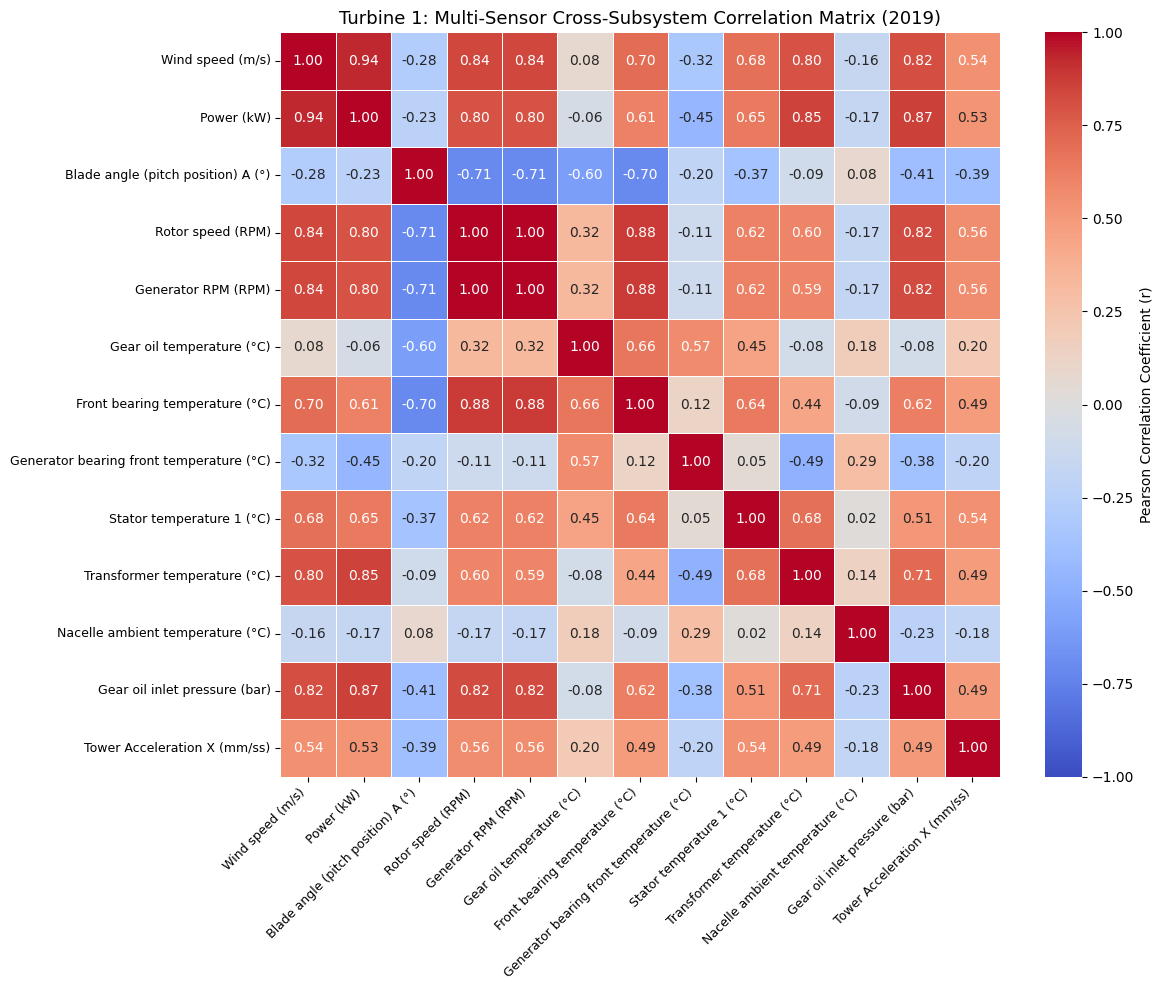

In [12]:
print(missing_summary.round(2))

# 3. Pearson Correlation Matrix calculate karein
corr_matrix = df_corr_subset.corr(method='pearson')

# 4. Correlation Heatmap plot karein
plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    vmin=-1.0,
    vmax=1.0,
    linewidths=0.5,
    cbar_kws={'label': 'Pearson Correlation Coefficient (r)'}
)
plt.title('Turbine 1: Multi-Sensor Cross-Subsystem Correlation Matrix (2019)', fontsize=13)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()

### 2.7 Second-event visual inspection

--- 1. Cross-Validating Second Hydraulic Failure Event ---


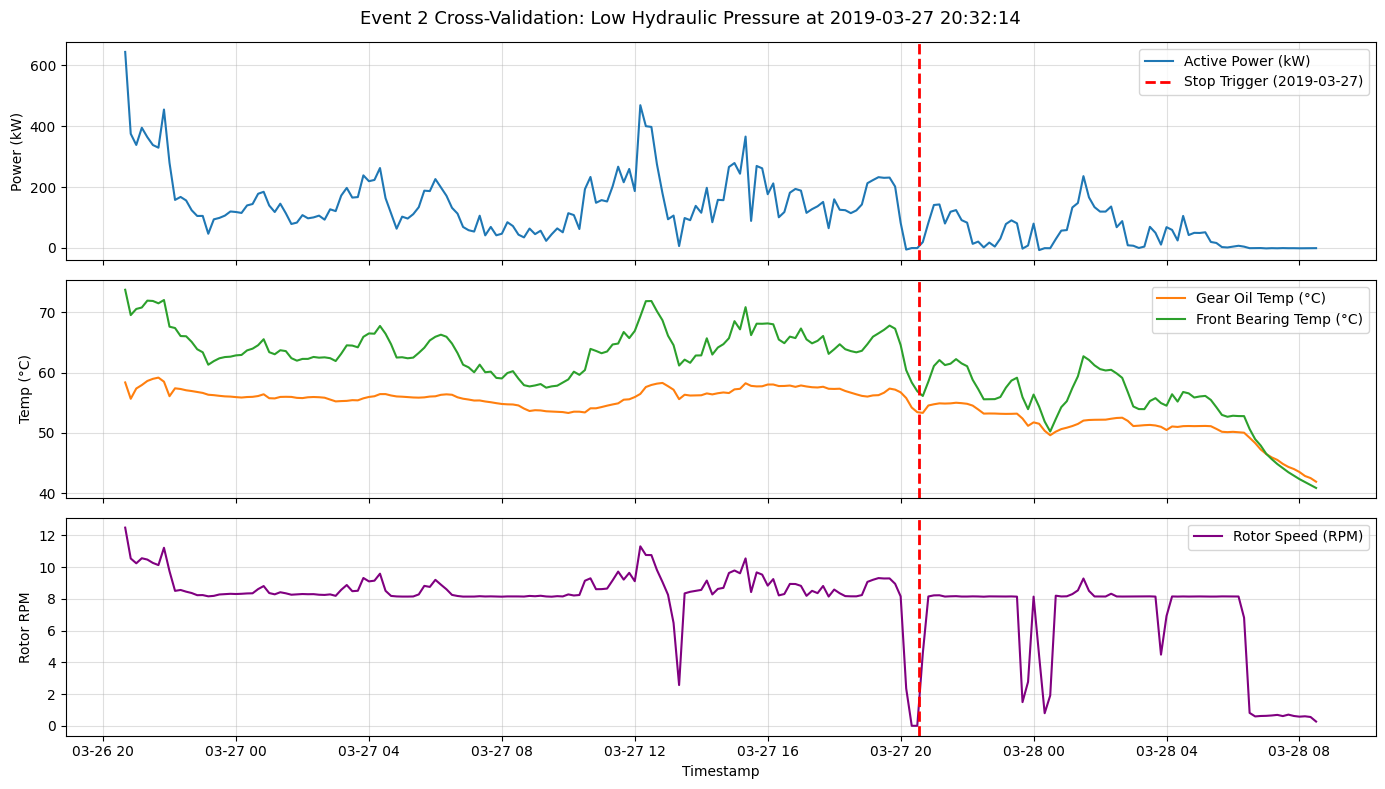


--- 2. Sensor Quality & Flatline Audit ---


In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. SECOND FAILURE EVENT CROSS-VALIDATION (2019-03-27)
# ---------------------------------------------------------
print("--- 1. Cross-Validating Second Hydraulic Failure Event ---")

# Second hydraulic event timestamp
target_time_2 = pd.to_datetime('2019-03-27 20:32:14')

# 24 hours prior, 12 hours after
start_win_2 = target_time_2 - pd.Timedelta(hours=24)
end_win_2 = target_time_2 + pd.Timedelta(hours=12)

# Ensure Date and time is datetime
df_t1['Date and time'] = pd.to_datetime(df_t1['Date and time'])

scada_win_2 = df_t1[(df_t1['Date and time'] >= start_win_2) & (df_t1['Date and time'] <= end_win_2)].copy()

# Plot multi-sensor behavior around second event
fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)

# Power
axes[0].plot(scada_win_2['Date and time'], scada_win_2['Power (kW)'], color='tab:blue', label='Active Power (kW)')
axes[0].axvline(target_time_2, color='red', linestyle='--', linewidth=2, label='Stop Trigger (2019-03-27)')
axes[0].set_ylabel('Power (kW)')

axes[0].legend(loc='upper right')
axes[0].grid(True, alpha=0.4)

# Gear Oil & Bearing Temperatures
axes[1].plot(scada_win_2['Date and time'], scada_win_2['Gear oil temperature (°C)'], color='tab:orange', label='Gear Oil Temp (°C)')
axes[1].plot(scada_win_2['Date and time'], scada_win_2['Front bearing temperature (°C)'], color='tab:green', label='Front Bearing Temp (°C)')
axes[1].axvline(target_time_2, color='red', linestyle='--', linewidth=2)
axes[1].set_ylabel('Temp (°C)')
axes[1].legend(loc='upper right')
axes[1].grid(True, alpha=0.4)

# Rotor RPM & Inlet Pressure
axes[2].plot(scada_win_2['Date and time'], scada_win_2['Rotor speed (RPM)'], color='purple', label='Rotor Speed (RPM)')
axes[2].axvline(target_time_2, color='red', linestyle='--', linewidth=2)
axes[2].set_ylabel('Rotor RPM')
axes[2].legend(loc='upper right')
axes[2].grid(True, alpha=0.4)

plt.suptitle('Event 2 Cross-Validation: Low Hydraulic Pressure at 2019-03-27 20:32:14', fontsize=13)
plt.xlabel('Timestamp')
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 2. SENSOR INTEGRITY & FROZEN / FLATLINE AUDIT
# ---------------------------------------------------------
print("\n--- 2. Sensor Quality & Flatline Audit ---")


In [14]:
core_channels = [
    'Wind speed (m/s)', 'Power (kW)', 'Rotor speed (RPM)',
    'Gear oil temperature (°C)', 'Front bearing temperature (°C)',
    'Gear oil inlet pressure (bar)', 'Tower Acceleration X (mm/ss)'
]

audit_records = []

for ch in core_channels:
    s = pd.to_numeric(df_t1[ch], errors='coerce')
    nan_pct = s.isnull().mean() * 100
    zero_pct = (s == 0).mean() * 100

    # Frozen check: consecutive identical values (> 6 consecutive 10-min readings = 1 hr flatline)
    diffs = s.diff().abs()
    frozen_runs = (diffs == 0).astype(int)
    max_consecutive_frozen = frozen_runs.groupby((frozen_runs != frozen_runs.shift()).cumsum()).cumsum().max()

    audit_records.append({
        'Sensor Channel': ch,
        'Missing / NaN (%)': round(nan_pct, 2),
        'Zero Readings (%)': round(zero_pct, 2),
        'Max Frozen Consecutive Steps': max_consecutive_frozen
    })

audit_df = pd.DataFrame(audit_records)
display(audit_df)

,Sensor Channel,Missing / NaN (%),Zero Readings (%),Max Frozen Consecutive Steps
0,Wind speed (m/s),0.16,0.00,1
1,Power (kW),0.16,0.00,1
2,Rotor speed (RPM),0.16,2.17,48
3,Gear oil temperature (°C),4.62,0.00,1
4,Front bearing temperature (°C),4.62,0.00,9
5,Gear oil inlet pressure (bar),0.16,0.21,6
6,Tower Acceleration X (mm/ss),4.62,0.00,0


### 2.8 Sensor-quality visual audit
The next chart visualizes missingness and frozen-sensor behaviour from the audit table.

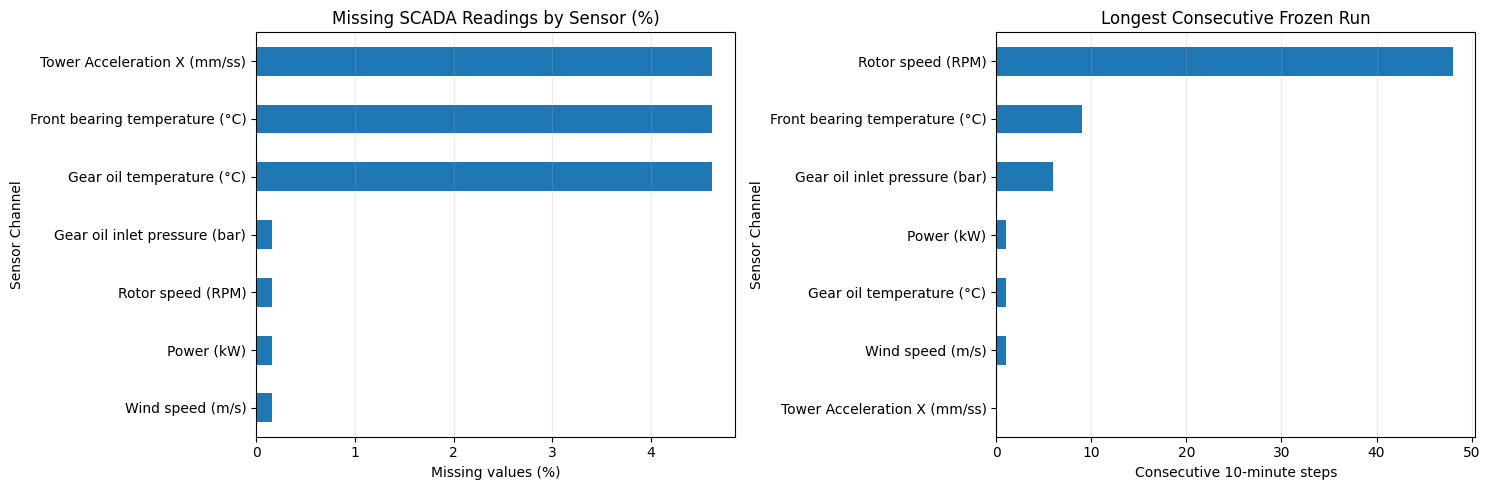

In [15]:

# Visual audit of missingness and frozen readings.
audit_plot = audit_df.copy()
audit_plot["Max Frozen Consecutive Steps"] = pd.to_numeric(
    audit_plot["Max Frozen Consecutive Steps"], errors="coerce"
).fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
audit_plot.set_index("Sensor Channel")["Missing / NaN (%)"].sort_values().plot(
    kind="barh", ax=axes[0], title="Missing SCADA Readings by Sensor (%)"
)
axes[0].set_xlabel("Missing values (%)")
axes[0].grid(axis="x", alpha=0.25)

audit_plot.set_index("Sensor Channel")["Max Frozen Consecutive Steps"].sort_values().plot(
    kind="barh", ax=axes[1], title="Longest Consecutive Frozen Run"
)
axes[1].set_xlabel("Consecutive 10-minute steps")
axes[1].grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()


## 3. Prepare SCADA data, event labels and chronological split

Run these cells after the API loading and EDA sections. They create the time-indexed modelling dataframe, label precursor/fault windows, and define the chronological train/test split.

In [16]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import Ridge
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import joblib

warnings.filterwarnings("ignore")

# Use the already-loaded Member 1 SCADA dataframe.
if "df_t1" not in globals():
    raise NameError("Run Member 1's SCADA loading cells first; df_t1 was not found.")

df_t1 = df_t1.copy()
df_t1["Date and time"] = pd.to_datetime(df_t1["Date and time"], errors="coerce")
df_t1 = (df_t1.dropna(subset=["Date and time"])
               .sort_values("Date and time")
               .drop_duplicates("Date and time")
               .set_index("Date and time"))

In [17]:
# Canonical short names mapped to source SCADA column names.
BASE = {
    "wind": "Wind speed (m/s)",
    "power": "Power (kW)",
    "pitch": "Blade angle (pitch position) A (°)",
    "rotor": "Rotor speed (RPM)",
    "gen_rpm": "Generator RPM (RPM)",
    "gear_oil": "Gear oil temperature (°C)",
    "front_brg": "Front bearing temperature (°C)",
    "gen_brg": "Generator bearing front temperature (°C)",
    "stator": "Stator temperature 1 (°C)",
    "trafo": "Transformer temperature (°C)",
    "ambient": "Nacelle ambient temperature (°C)",
    "oil_press": "Gear oil inlet pressure (bar)",
    "tower_acc": "Tower Acceleration X (mm/ss)",
}

missing_columns = [v for v in BASE.values() if v not in df_t1.columns]
if missing_columns:
    print("Columns not available and skipped:", missing_columns)
BASE = {k: v for k, v in BASE.items() if v in df_t1.columns}

df = df_t1[list(BASE.values())].apply(pd.to_numeric, errors="coerce").copy()

In [18]:
df.columns = list(BASE.keys())

# Reindex to the expected 10-minute SCADA interval.
full_index = pd.date_range(df.index.min(), df.index.max(), freq="10min")
df = df.reindex(full_index)
df.index.name = "timestamp"

# Interpolate only short internal gaps (maximum 30 minutes).
missing_before = df.isna().mean().mul(100).round(2)
df = df.interpolate(method="time", limit=3, limit_area="inside")

# Basic physical sanity checks.
for col in ["wind", "rotor", "gen_rpm", "power"]:
    if col in df.columns:
        df.loc[df[col] < 0, col] = np.nan

print("SCADA rows:", len(df))
print("Date range:", df.index.min(), "to", df.index.max())
print("\nMissing percentage before short-gap interpolation:")
display(missing_before.rename("missing_pct").to_frame())
print("\nMissing percentage after interpolation:")
display(df.isna().mean().mul(100).round(2).rename("missing_pct").to_frame())

SCADA rows: 52560
Date range: 2019-01-01 00:00:00 to 2019-12-31 23:50:00

Missing percentage before short-gap interpolation:


,missing_pct
wind,0.16
power,0.16
pitch,4.62
rotor,0.16
gen_rpm,0.16
gear_oil,4.62
front_brg,4.62
gen_brg,0.16
stator,0.16
trafo,4.62



Missing percentage after interpolation:


,missing_pct
wind,0.13
power,9.76
pitch,4.58
rotor,0.13
gen_rpm,0.13
gear_oil,4.58
front_brg,4.58
gen_brg,0.13
stator,0.13
trafo,4.58


In [19]:
# Event timestamps preserved from Member 2's original notebook.
hydraulic_faults = pd.to_datetime([
    "2019-02-24 02:31:49",
    "2019-03-27 20:32:14",
])

PRECURSOR_HOURS = 24
FAULT_HOURS = 2

df["precursor"] = 0
df["fault_active"] = 0

for event_time in hydraulic_faults:
    precursor_start = event_time - pd.Timedelta(hours=PRECURSOR_HOURS)
    fault_end = event_time + pd.Timedelta(hours=FAULT_HOURS)
    df.loc[(df.index >= precursor_start) & (df.index < event_time), "precursor"] = 1
    df.loc[(df.index >= event_time) & (df.index <= fault_end), "fault_active"] = 1

# Operating-state indicator; keep fault labels separately.
df["operating"] = 1
if all(c in df.columns for c in ["wind", "power", "rotor"]):
    stopped_despite_wind = (df["wind"] > 3.0) & (df["power"] <= 0) & (df["rotor"] < 1)
    df.loc[stopped_despite_wind, "operating"] = 0

In [20]:
df.loc[df["fault_active"] == 1, "operating"] = 0

# Hold out the complete 24-hour precursor window before event 2 and everything after it.
# Event 1 remains in training; event 2 is the held-out event.
split_time = hydraulic_faults[1] - pd.Timedelta(hours=PRECURSOR_HOURS)
base_train = df.index < split_time
base_test = df.index >= split_time

print("Split timestamp:", split_time)
print("Train rows:", int(base_train.sum()), "| Test rows:", int(base_test.sum()))
print("Train precursor rows:", int(df.loc[base_train, "precursor"].sum()))
print("Test precursor rows:", int(df.loc[base_test, "precursor"].sum()))
print("Train active-fault rows:", int(df.loc[base_train, "fault_active"].sum()))
print("Test active-fault rows:", int(df.loc[base_test, "fault_active"].sum()))

Split timestamp: 2019-03-26 20:32:14
Train rows: 12220 | Test rows: 40340
Train precursor rows: 144
Test precursor rows: 144
Train active-fault rows: 12
Test active-fault rows: 12


## 4. Member 2 — Feature engineering

Feature engineering uses normal training observations to estimate expected operating behaviour. Execute the cells in order.

In [21]:
# Normal training rows are used to learn expected operating behaviour.
normal_train = base_train & (df["precursor"] == 0) & (df["fault_active"] == 0) & (df["operating"] == 1)

feat = df[list(BASE.keys())].copy()

# A. Power-curve deviation: expected power is estimated from normal training data.
if {"wind", "power"}.issubset(df.columns):
    train_curve = df.loc[normal_train, ["wind", "power"]].dropna().copy()
    bins = np.arange(0, 25.5, 0.5)
    train_curve["wind_bin"] = pd.cut(train_curve["wind"], bins=bins)
    curve = (train_curve.groupby("wind_bin", observed=True)
                        .agg(wind_mid=("wind", "median"), expected_power=("power", "median"))
                        .dropna()
                        .sort_values("wind_mid"))
    if len(curve) >= 2:
        expected = np.interp(df["wind"], curve["wind_mid"], curve["expected_power"])
        expected = pd.Series(expected, index=df.index).where(df["wind"].notna())
        feat["power_expected"] = expected
        feat["power_dev"] = df["power"] - expected
        feat["power_ratio"] = (df["power"] / expected.where(expected >= 50))
    else:
        print("Warning: insufficient normal training data to estimate a power curve.")

In [22]:
# B. Thermal residuals: predict component temperature from load/ambient/rotor conditions.
thermal_predictors = [c for c in ["power", "ambient", "rotor"] if c in df.columns]
if "power" in df.columns:
    df["power_sq"] = df["power"] ** 2 / 1000
    if "power_sq" not in thermal_predictors:
        thermal_predictors.append("power_sq")

def add_thermal_residual(target_col, output_name):
    predictors = [c for c in thermal_predictors if c in df.columns]
    if target_col not in df.columns or len(predictors) < 2:
        return
    fit_data = df.loc[normal_train, predictors + [target_col]].dropna()
    if len(fit_data) < 100:
        print(f"Skipping {output_name}: not enough normal training rows ({len(fit_data)}).")
        return
    model = Ridge(alpha=1.0)
    model.fit(fit_data[predictors], fit_data[target_col])
    valid = df[predictors].notna().all(axis=1)
    prediction = pd.Series(np.nan, index=df.index, dtype=float)
    prediction.loc[valid] = model.predict(df.loc[valid, predictors])
    feat[output_name] = df[target_col] - prediction

In [23]:
for source_col, output_col in [
    ("gear_oil", "gear_oil_res"),
    ("front_brg", "front_brg_res"),
    ("gen_brg", "gen_brg_res"),
    ("stator", "stator_res"),
]:
    add_thermal_residual(source_col, output_col)

# C. Sensor differentials and physical ratios.
def add_difference(a, b, name):
    if a in df.columns and b in df.columns:
        feat[name] = df[a] - df[b]

add_difference("gear_oil", "ambient", "gear_minus_amb")
add_difference("front_brg", "ambient", "frontbrg_minus_amb")
add_difference("gen_brg", "gear_oil", "genbrg_minus_gear")
add_difference("stator", "ambient", "stator_minus_amb")
add_difference("trafo", "ambient", "trafo_minus_amb")
add_difference("gear_oil", "front_brg", "gear_minus_frontbrg")

if {"gen_rpm", "rotor"}.issubset(df.columns):
    feat["rpm_ratio"] = (df["gen_rpm"] / df["rotor"].where(df["rotor"] > 1))

In [24]:
# D. Trailing rolling statistics (10-minute samples).
windows = {"1h": 6, "6h": 36, "24h": 144}
rolling_signals = [c for c in [
    "power_dev", "gear_oil_res", "front_brg_res", "gen_brg_res", "stator_res",
    "oil_press", "tower_acc", "pitch", "rpm_ratio"
] if c in feat.columns]

for signal in rolling_signals:
    for window_name, window_size in windows.items():
        rolling = feat[signal].rolling(window_size, min_periods=max(2, window_size // 2))
        feat[f"{signal}_mean_{window_name}"] = rolling.mean()
        feat[f"{signal}_std_{window_name}"] = rolling.std()

for signal in [c for c in ["gear_oil_res", "front_brg_res", "gen_brg_res", "stator_res", "power_dev"] if c in feat.columns]:
    mean_1h = f"{signal}_mean_1h"
    if mean_1h in feat.columns:
        feat[f"{signal}_trend_6h"] = feat[mean_1h].diff(36)

# E. Cyclical time features; retained for supervised models but excluded from PCA.
hour = feat.index.hour + feat.index.minute / 60
month = feat.index.month
feat["hour_sin"] = np.sin(2 * np.pi * hour / 24)
feat["hour_cos"] = np.cos(2 * np.pi * hour / 24)

In [25]:
feat["month_sin"] = np.sin(2 * np.pi * month / 12)
feat["month_cos"] = np.cos(2 * np.pi * month / 12)

# Attach labels and split marker.
for label_col in ["precursor", "fault_active", "operating"]:
    feat[label_col] = df[label_col]
feat["is_train"] = base_train.astype(int)

print("Engineered dataset shape:", feat.shape)
print("Engineered feature count (excluding labels/time):",
      len([c for c in feat.columns if c not in ["precursor", "fault_active", "operating", "is_train"]]))
display(feat.head())

Engineered dataset shape: (52560, 94)
Engineered feature count (excluding labels/time): 90


,wind,power,pitch,rotor,gen_rpm,gear_oil,front_brg,gen_brg,stator,trafo,...,stator_res_trend_6h,power_dev_trend_6h,hour_sin,hour_cos,month_sin,month_cos,precursor,fault_active,operating,is_train
timestamp,,,,,,,,,,,,,,,,,,,,,
2019-01-01 00:00:00,4.454060,191.814896,0.074493,8.880423,1055.634033,57.302498,68.132500,41.955002,59.902500,36.375000,...,NaN,NaN,0.000000,1.000000,0.5,0.866025,0,0,1,1
2019-01-01 00:10:00,4.331436,189.524963,0.062499,8.859600,1053.627930,57.117500,66.580002,42.577499,60.900002,35.982502,...,NaN,NaN,0.043619,0.999048,0.5,0.866025,0,0,1,1
2019-01-01 00:20:00,5.447210,381.144653,0.000000,10.601379,1258.793335,57.752499,69.660004,43.209999,61.757500,35.622501,...,NaN,NaN,0.087156,0.996195,0.5,0.866025,0,0,1,1
2019-01-01 00:30:00,5.472900,422.717590,0.000000,10.916513,1297.343994,58.842499,72.739998,43.887501,62.017502,35.595001,...,NaN,NaN,0.130526,0.991445,0.5,0.866025,0,0,1,1
2019-01-01 00:40:00,5.601278,307.518646,0.000000,9.997338,1187.462891,59.025002,71.840004,44.522499,62.197502,35.347500,...,NaN,NaN,0.173648,0.984808,0.5,0.866025,0,0,1,1


### 4.1 Visualize engineered feature behaviour
These plots check whether the engineered power-curve deviation and thermal residuals vary meaningfully over time. They are diagnostics, not evidence of predictive performance.

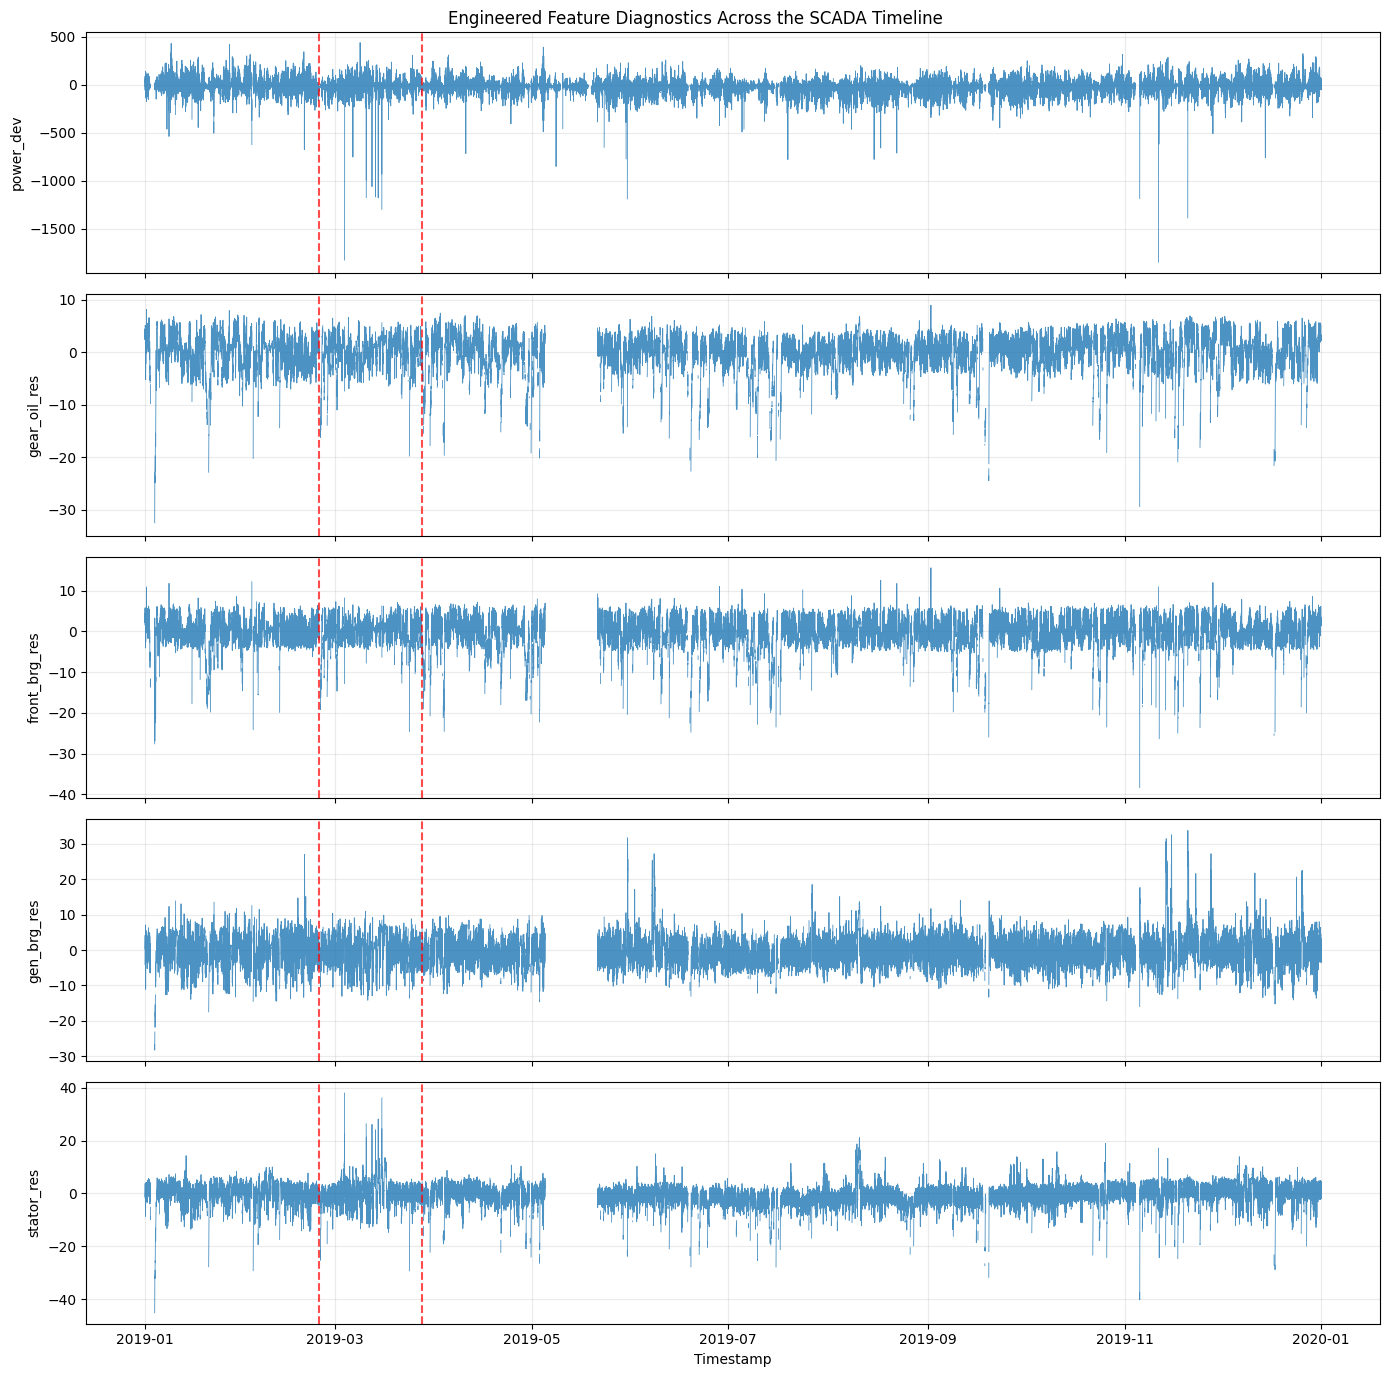

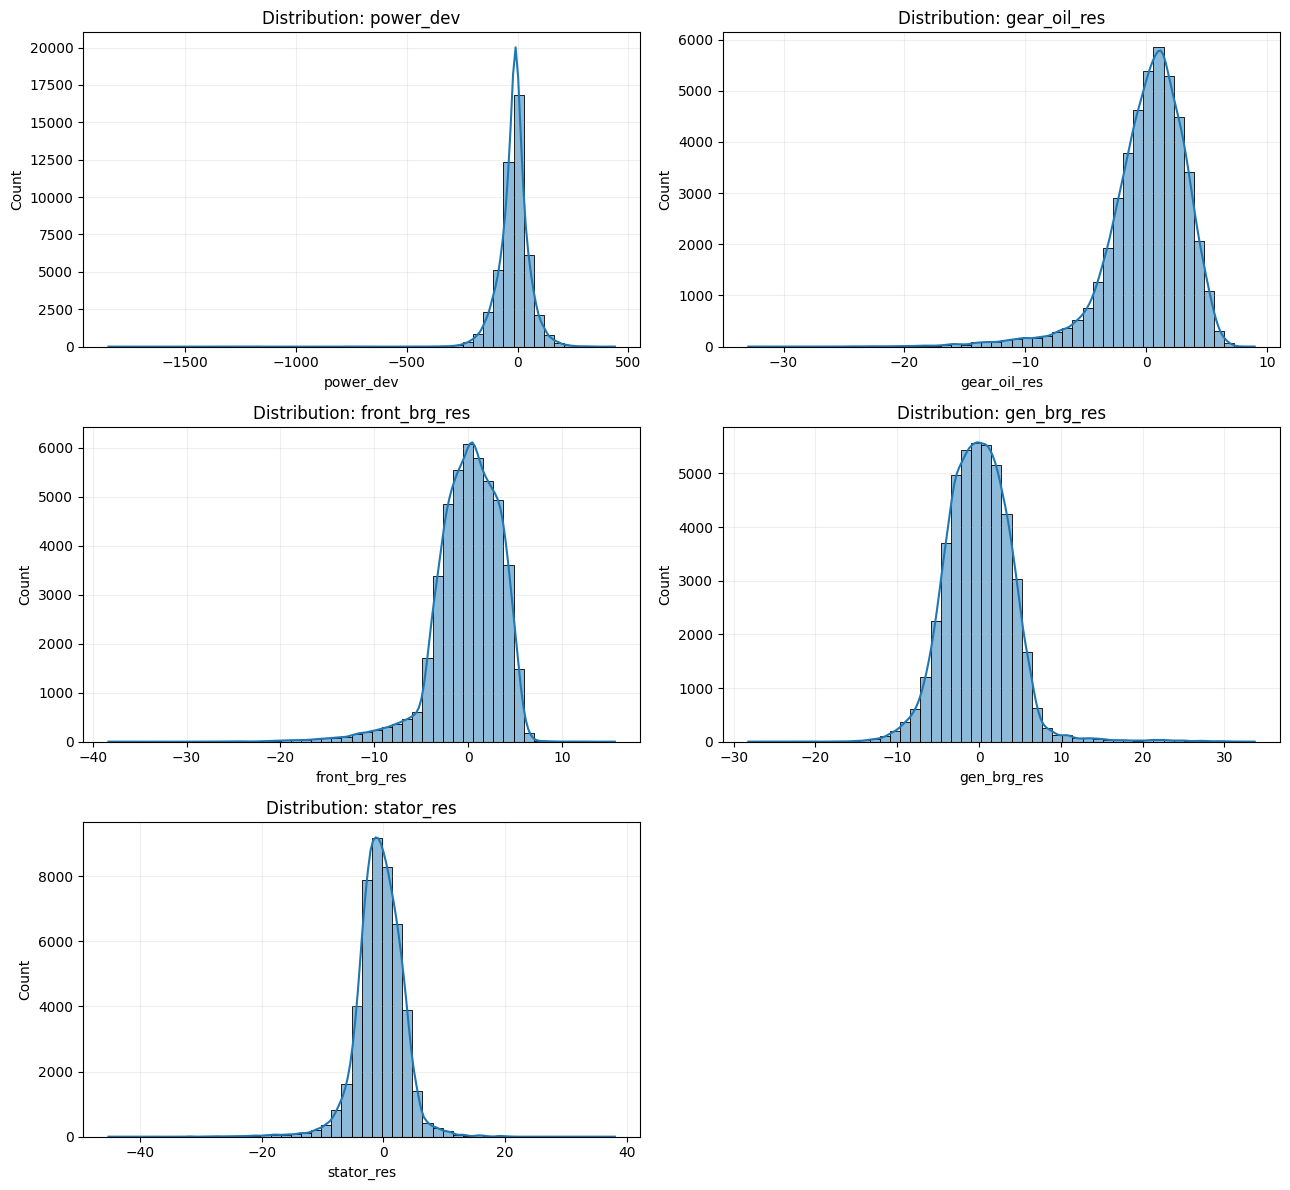

In [26]:

# Engineered-feature diagnostics: power deviation and thermal residuals.
plot_cols = [c for c in ["power_dev", "gear_oil_res", "front_brg_res", "gen_brg_res", "stator_res"]
             if c in feat.columns]
if plot_cols:
    fig, axes = plt.subplots(len(plot_cols), 1, figsize=(14, 2.8 * len(plot_cols)), sharex=True)
    if len(plot_cols) == 1:
        axes = [axes]
    for ax, col in zip(axes, plot_cols):
        ax.plot(feat.index, feat[col], linewidth=0.6, alpha=0.8)
        ax.set_ylabel(col)
        ax.grid(alpha=0.25)
        for event_time in hydraulic_faults:
            ax.axvline(event_time, color="red", linestyle="--", alpha=0.7)
    axes[-1].set_xlabel("Timestamp")
    fig.suptitle("Engineered Feature Diagnostics Across the SCADA Timeline")
    plt.tight_layout()
    plt.show()
else:
    print("No power-deviation or thermal-residual features were available to plot.")

# Distribution check for the principal engineered features.
dist_cols = [c for c in ["power_dev", "gear_oil_res", "front_brg_res", "gen_brg_res", "stator_res"]
             if c in feat.columns and feat[c].notna().any()]
if dist_cols:
    ncols = 2
    nrows = int(np.ceil(len(dist_cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(13, 4 * nrows))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, dist_cols):
        sns.histplot(feat[col].dropna(), bins=50, kde=True, ax=ax)
        ax.set_title(f"Distribution: {col}")
        ax.grid(alpha=0.2)
    for ax in axes[len(dist_cols):]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()


## 5. PCA preprocessing and component selection

In [27]:
label_cols = ["precursor", "fault_active", "operating", "is_train"]
time_cols = ["hour_sin", "hour_cos", "month_sin", "month_cos"]
excluded = set(label_cols + time_cols)

candidate_features = [
    c for c in feat.columns
    if c not in excluded and pd.api.types.is_numeric_dtype(feat[c])
]

# Drop features that are entirely missing or constant on normal training rows.
fit_rows = normal_train.reindex(feat.index, fill_value=False)
X_fit_raw = feat.loc[fit_rows, candidate_features].replace([np.inf, -np.inf], np.nan)

all_missing = X_fit_raw.columns[X_fit_raw.isna().all()].tolist()
candidate_features = [c for c in candidate_features if c not in all_missing]
X_fit_raw = X_fit_raw[candidate_features]

low_variance = X_fit_raw.columns[X_fit_raw.nunique(dropna=True) <= 1].tolist()
candidate_features = [c for c in candidate_features if c not in low_variance]

# Remove one of each highly correlated pair, based on training-normal rows only.
corr_input = X_fit_raw[candidate_features].copy()
corr_input = corr_input.fillna(corr_input.median())
corr_matrix = corr_input.corr().abs()

In [28]:
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr = [col for col in upper.columns if (upper[col] > 0.98).any()]
FEATURES = [c for c in candidate_features if c not in high_corr]

if len(FEATURES) < 2:
    raise ValueError("Fewer than two usable features remain. Inspect sensor availability and feature engineering.")

X_all_raw = feat[FEATURES].replace([np.inf, -np.inf], np.nan)
imputer = SimpleImputer(strategy="median")
imputer.fit(X_all_raw.loc[fit_rows])

X_all_imputed = pd.DataFrame(
    imputer.transform(X_all_raw),
    index=feat.index,
    columns=FEATURES
)

scaler = StandardScaler()
scaler.fit(X_all_imputed.loc[fit_rows])
Z_all = pd.DataFrame(
    scaler.transform(X_all_imputed),
    index=feat.index,
    columns=FEATURES
)

In [29]:
Z_fit = Z_all.loc[fit_rows]

# Retain enough components to explain at least 95% variance, bounded by matrix dimensions.
pca_full = PCA(random_state=42)
pca_full.fit(Z_fit)
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)
N_COMP = int(np.searchsorted(cumulative_variance, 0.95) + 1)
N_COMP = max(1, min(N_COMP, Z_fit.shape[0], Z_fit.shape[1]))

pca = PCA(n_components=N_COMP, random_state=42)
pca.fit(Z_fit)

scores = pd.DataFrame(
    pca.transform(Z_all),
    index=Z_all.index,
    columns=[f"PC{i+1}" for i in range(N_COMP)]
)
loadings = pd.DataFrame(
    pca.components_.T,
    index=FEATURES,
    columns=scores.columns
)

print(f"Features retained: {len(FEATURES)}")

Features retained: 84


In [30]:
print(f"Features removed — all missing: {len(all_missing)}, low variance: {len(low_variance)}, high correlation: {len(high_corr)}")
print(f"PCA components selected: {N_COMP}")
print(f"Cumulative explained variance: {pca.explained_variance_ratio_.sum()*100:.2f}%")
display(pd.DataFrame({
    "component": scores.columns,
    "explained_variance_ratio": pca.explained_variance_ratio_,
    "cumulative_variance": np.cumsum(pca.explained_variance_ratio_)
}))

Features removed — all missing: 0, low variance: 0, high correlation: 2
PCA components selected: 41
Cumulative explained variance: 95.32%


,component,explained_variance_ratio,cumulative_variance
0,PC1,0.194988,0.194988
1,PC2,0.119752,0.314740
2,PC3,0.073146,0.387886
3,PC4,0.060559,0.448445
4,PC5,0.048098,0.496543
5,PC6,0.042765,0.539308
6,PC7,0.040017,0.579325
7,PC8,0.032333,0.611658
8,PC9,0.030173,0.641831
9,PC10,0.027939,0.669769


### 5.1 Feature correlation diagnostic
This heatmap uses the candidate features after the high-correlation filtering inputs have been imputed from normal training rows.

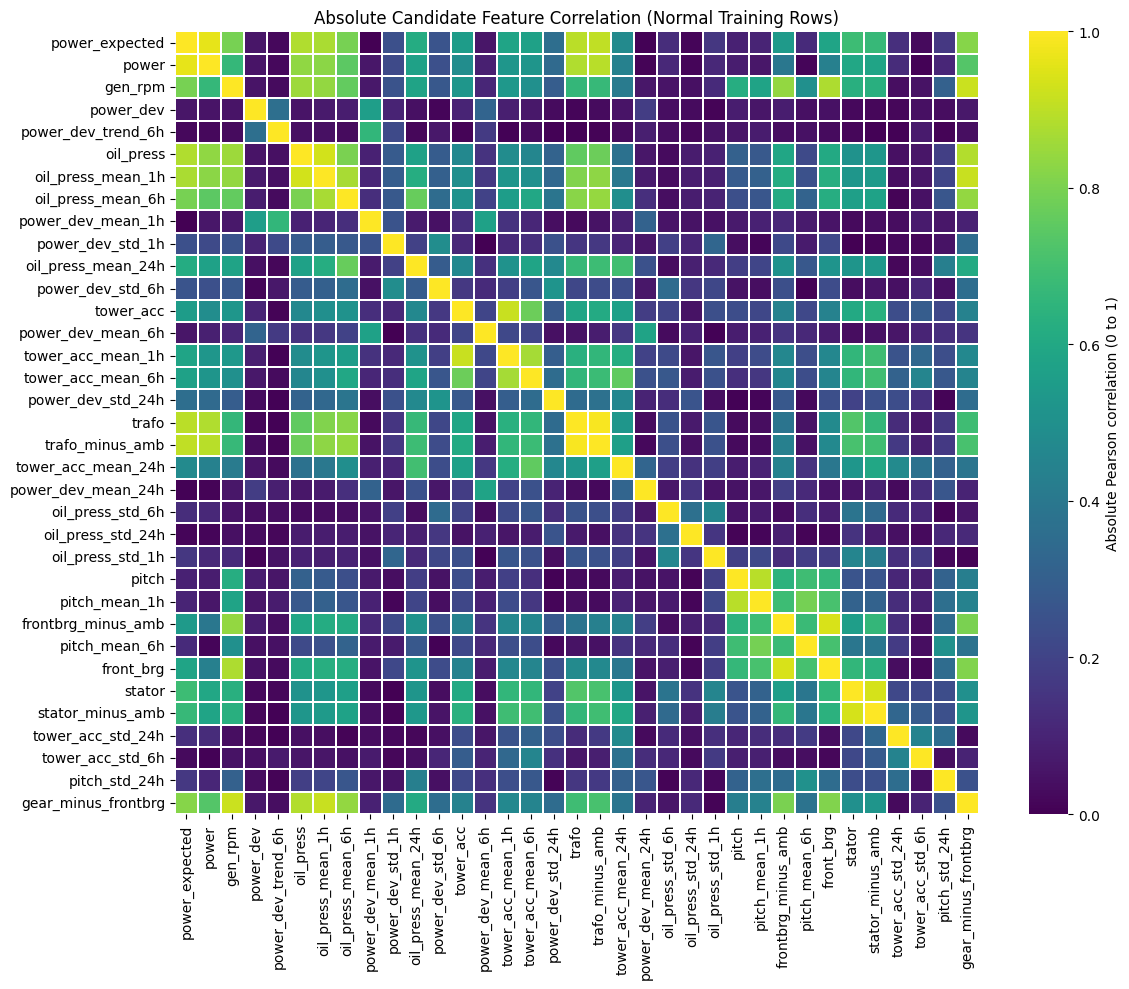

In [31]:

# Correlation heatmap before removing highly correlated predictors.
max_heatmap_features = 35
if corr_matrix.shape[0] > max_heatmap_features:
    # Show the most variable features to keep the heatmap readable.
    ranked = X_fit_raw[candidate_features].var().sort_values(ascending=False)
    heatmap_features = ranked.head(max_heatmap_features).index
    corr_plot = corr_matrix.loc[heatmap_features, heatmap_features]
else:
    corr_plot = corr_matrix

plt.figure(figsize=(12, 10))
sns.heatmap(corr_plot, cmap="viridis", vmin=0, vmax=1,
            linewidths=0.2, cbar_kws={"label": "Absolute Pearson correlation (0 to 1)"})
plt.title("Absolute Candidate Feature Correlation (Normal Training Rows)")
plt.tight_layout()
plt.show()


### 5.2 PCA explained-variance selection plot

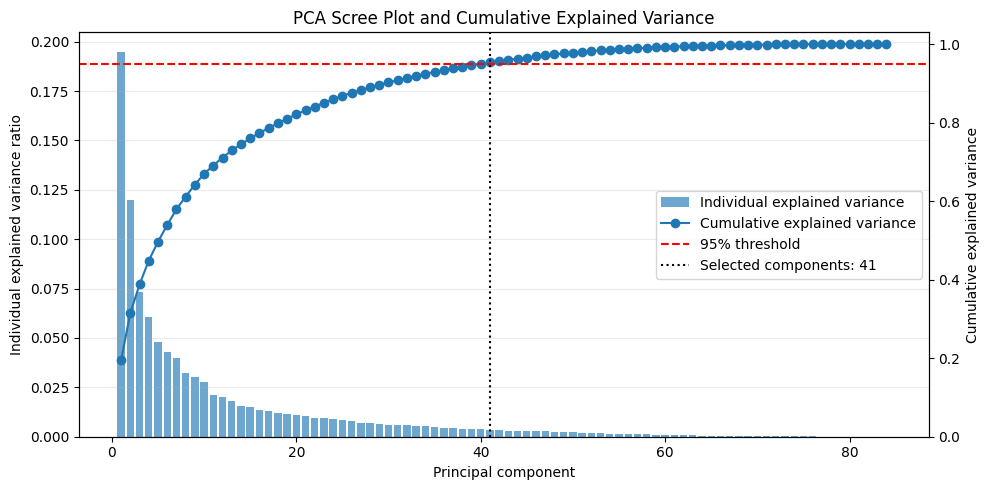

In [32]:

# Scree plot and cumulative explained variance used to select the 95% threshold.
fig, ax1 = plt.subplots(figsize=(10, 5))
component_numbers = np.arange(1, len(pca_full.explained_variance_ratio_) + 1)
ax1.bar(component_numbers, pca_full.explained_variance_ratio_, alpha=0.65,
        label="Individual explained variance")
ax1.set_xlabel("Principal component")
ax1.set_ylabel("Individual explained variance ratio")
ax1.set_title("PCA Scree Plot and Cumulative Explained Variance")
ax1.grid(axis="y", alpha=0.25)

ax2 = ax1.twinx()
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
ax2.plot(component_numbers, cum_var, marker="o", linewidth=1.5,
         label="Cumulative explained variance")
ax2.axhline(0.95, color="red", linestyle="--", label="95% threshold")
ax2.axvline(N_COMP, color="black", linestyle=":", label=f"Selected components: {N_COMP}")
ax2.set_ylabel("Cumulative explained variance")
ax2.set_ylim(0, 1.03)
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="center right")
plt.tight_layout()
plt.show()


## 6. PCA interpretation

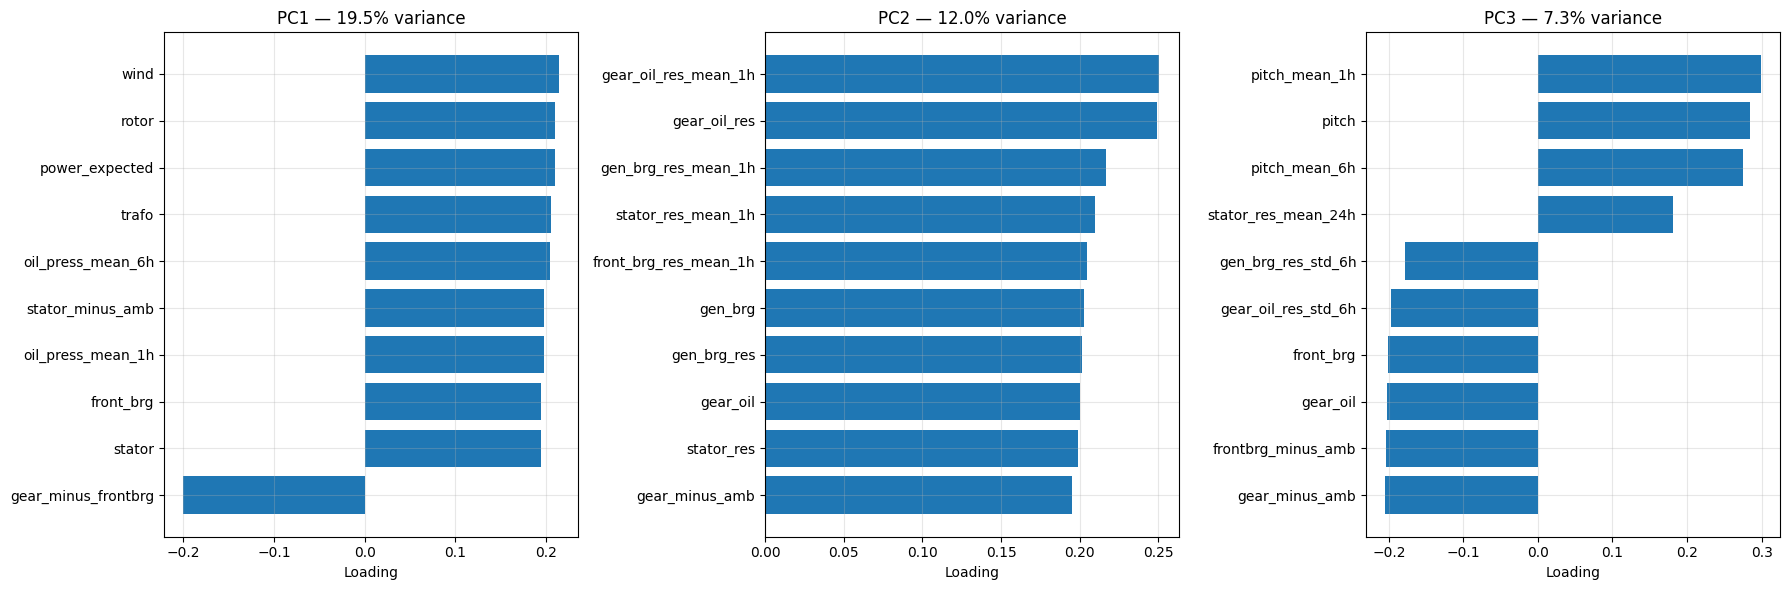

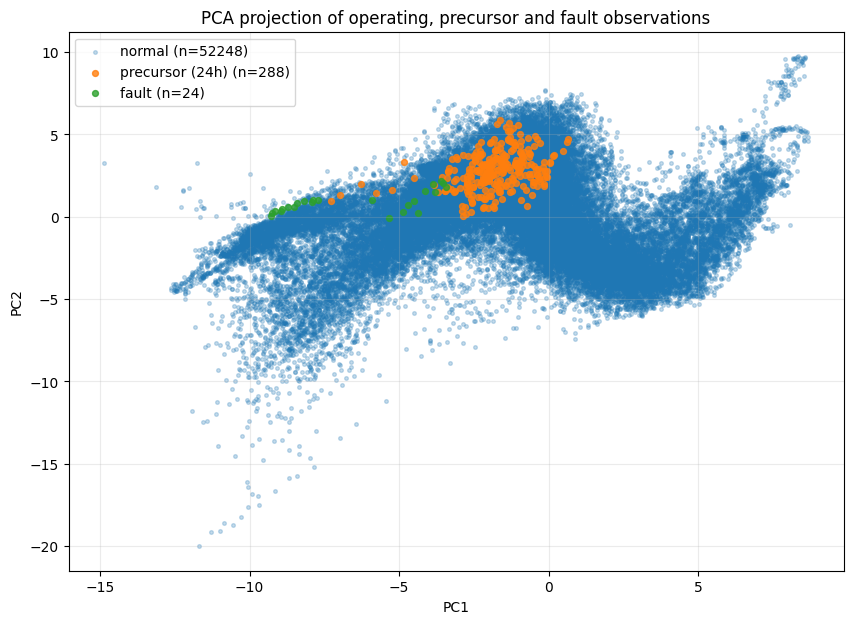

In [33]:
n_plot = min(3, N_COMP)
fig, axes = plt.subplots(1, n_plot, figsize=(6 * n_plot, 6))
if n_plot == 1:
    axes = [axes]

for i, ax in enumerate(axes):
    pc = f"PC{i+1}"
    top = loadings[pc].reindex(loadings[pc].abs().sort_values(ascending=False).index).head(10)
    top = top.sort_values()
    ax.barh(top.index, top.values)
    ax.set_title(f"{pc} — {pca.explained_variance_ratio_[i]*100:.1f}% variance")
    ax.set_xlabel("Loading")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

state = np.where(feat["fault_active"].eq(1), "fault",
         np.where(feat["precursor"].eq(1), "precursor (24h)", "normal"))

if N_COMP >= 2:
    plt.figure(figsize=(10, 7))
    for label in ["normal", "precursor (24h)", "fault"]:
        mask = state == label
        if mask.any():
            plt.scatter(scores.loc[mask, "PC1"], scores.loc[mask, "PC2"],
                        s=7 if label == "normal" else 18,
                        alpha=0.25 if label == "normal" else 0.8,
                        label=f"{label} (n={int(mask.sum())})")
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.title("PCA projection of operating, precursor and fault observations")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()
else:
    print("Only one component was retained; a 2D PCA scatterplot is not available.")

## 7. PCA anomaly detection — Hotelling T² and SPE

In [34]:
S = scores.values
Z = Z_all.values
reconstructed = pca.inverse_transform(S)

spe = ((Z - reconstructed) ** 2).sum(axis=1)
t2 = ((S ** 2) / pca.explained_variance_).sum(axis=1)

anom = pd.DataFrame({"T2": t2, "SPE": spe}, index=Z_all.index)

normal_fit_index = fit_rows[fit_rows].index
lim_t2 = anom.loc[normal_fit_index, "T2"].quantile(0.99)
lim_spe = anom.loc[normal_fit_index, "SPE"].quantile(0.99)

anom["alarm"] = ((anom["T2"] > lim_t2) | (anom["SPE"] > lim_spe)).astype(int)
anom["state"] = state
anom["is_train"] = feat["is_train"]

print("PCA anomaly thresholds — fitted on normal training rows")
print("T² 99th percentile:", round(float(lim_t2), 4))
print("SPE 99th percentile:", round(float(lim_spe), 4))
print("\nAlarm rate by state (%):")
display((anom.groupby("state")["alarm"].mean().mul(100).round(2)).rename("alarm_rate_pct").to_frame())

PCA anomaly thresholds — fitted on normal training rows
T² 99th percentile: 231.2309
SPE 99th percentile: 19.4764

Alarm rate by state (%):


,alarm_rate_pct
state,
fault,20.83
normal,3.94
precursor (24h),0.69


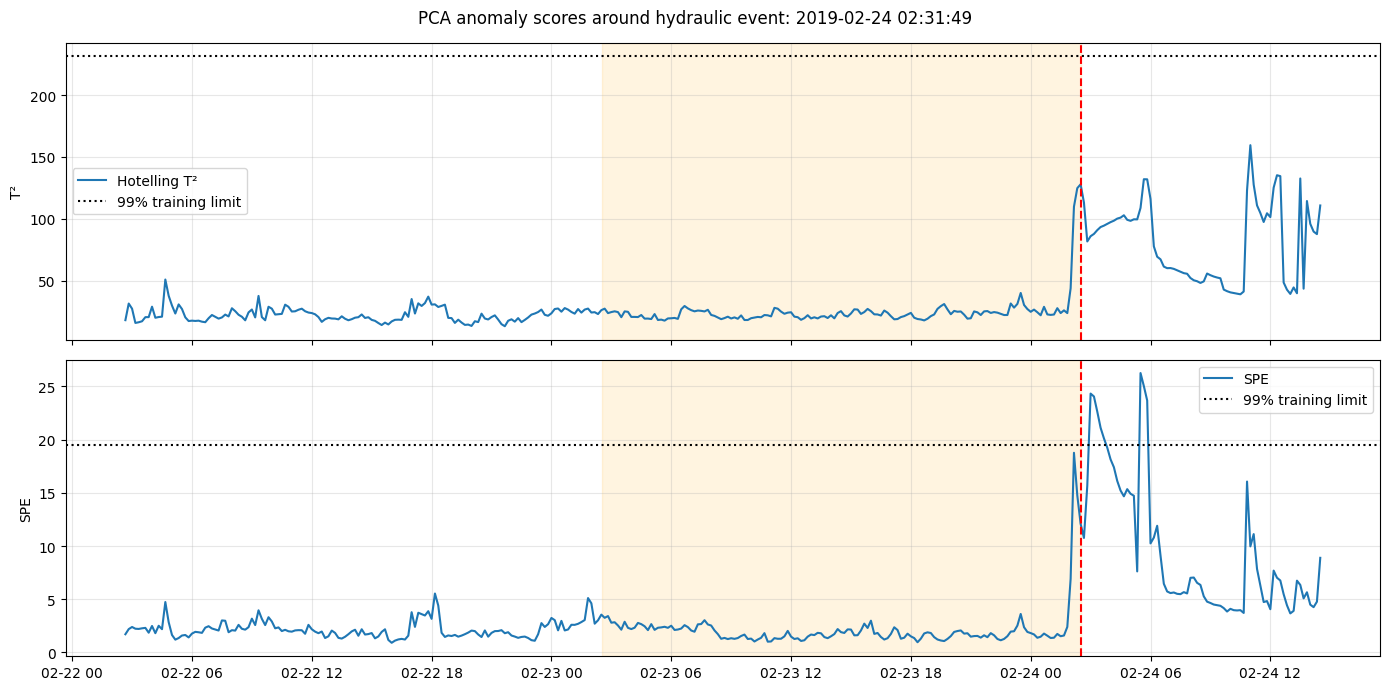

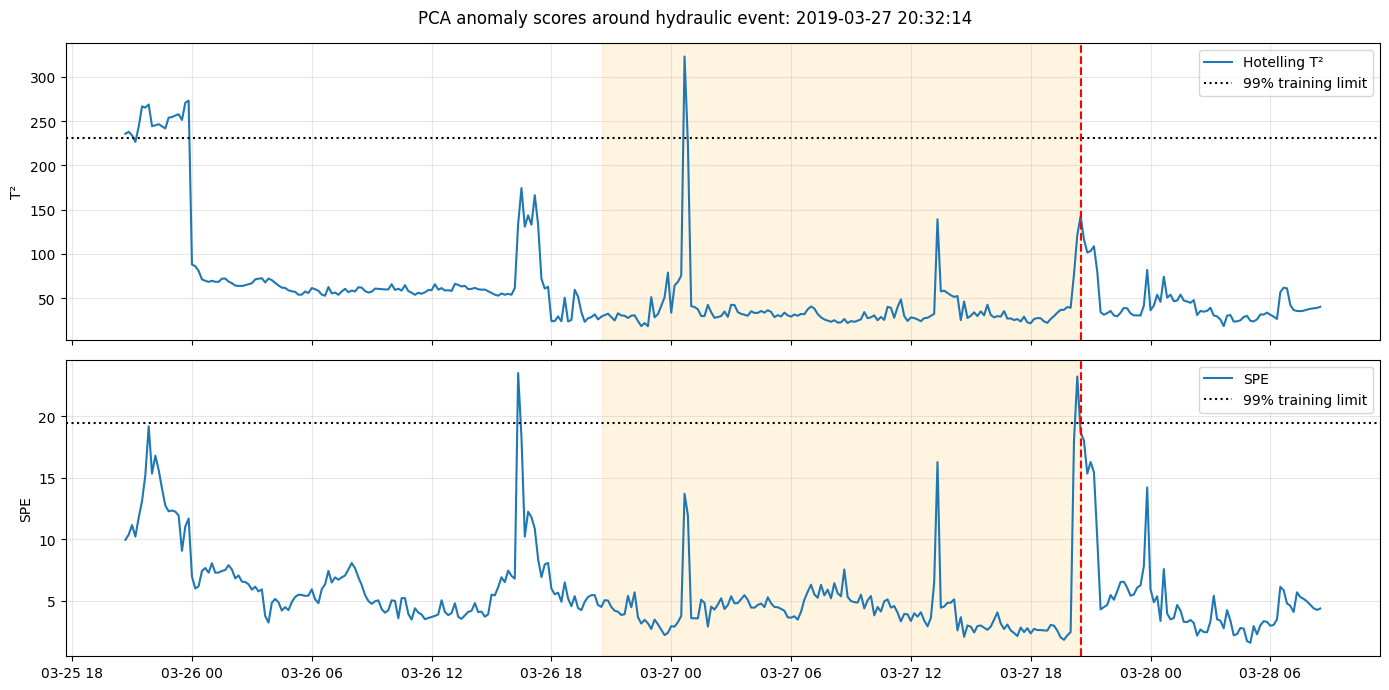

In [35]:
# Plot scores around each labelled event.
for event_time in hydraulic_faults:
    start = event_time - pd.Timedelta(hours=48)
    end = event_time + pd.Timedelta(hours=12)
    window = anom.loc[(anom.index >= start) & (anom.index <= end)]

    if window.empty:
        print("No SCADA rows around event:", event_time)
        continue

    fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
    axes[0].plot(window.index, window["T2"], label="Hotelling T²")
    axes[0].axhline(lim_t2, color="black", linestyle=":", label="99% training limit")
    axes[0].set_ylabel("T²")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(window.index, window["SPE"], label="SPE")
    axes[1].axhline(lim_spe, color="black", linestyle=":", label="99% training limit")
    axes[1].set_ylabel("SPE")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    for ax in axes:
        ax.axvline(event_time, color="red", linestyle="--", label="Failure event")
        ax.axvspan(event_time - pd.Timedelta(hours=PRECURSOR_HOURS), event_time,
                   color="orange", alpha=0.12)
    plt.suptitle(f"PCA anomaly scores around hydraulic event: {event_time}")
    plt.tight_layout()
    plt.show()

### 7.1 Overall PCA anomaly-score diagnostics

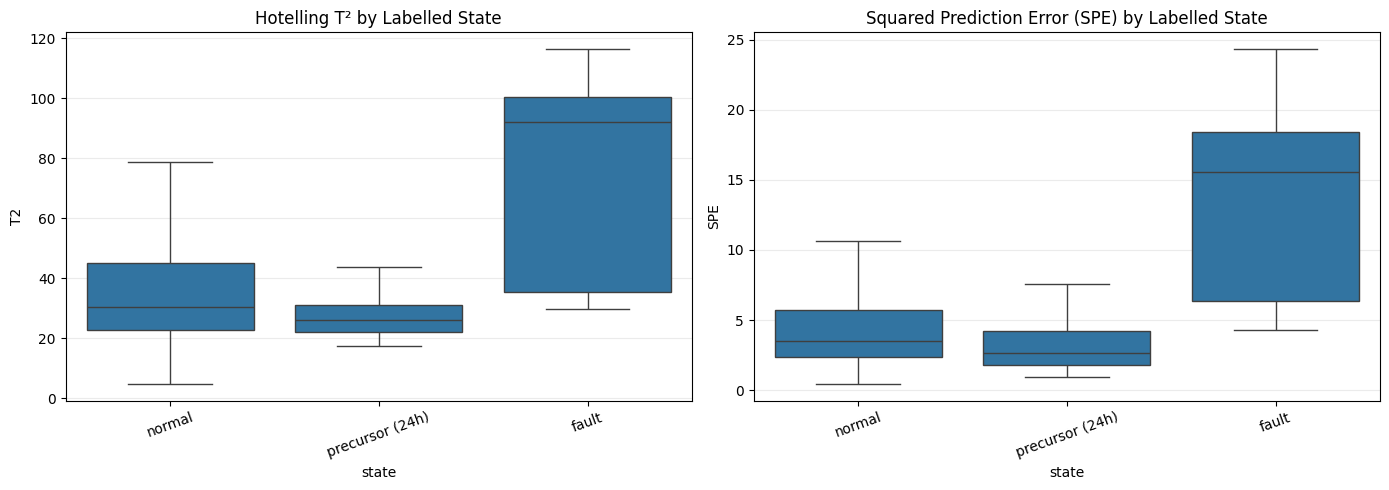

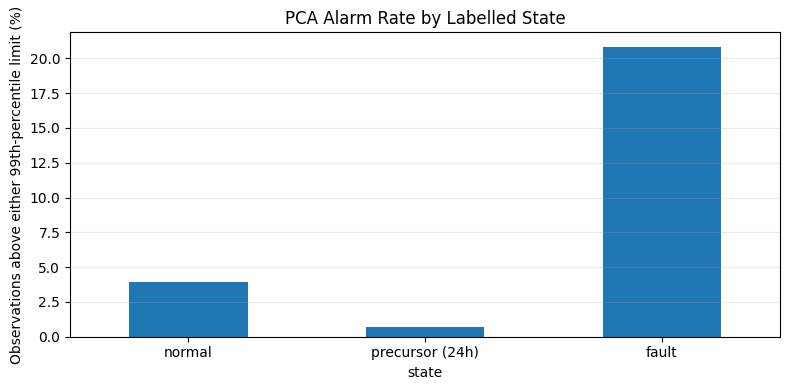

In [36]:

# Compare T² and SPE distributions and alarm rates by operating state.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=anom, x="state", y="T2", showfliers=False, ax=axes[0])
axes[0].set_title("Hotelling T² by Labelled State")
axes[0].tick_params(axis="x", rotation=20)
axes[0].grid(axis="y", alpha=0.25)

sns.boxplot(data=anom, x="state", y="SPE", showfliers=False, ax=axes[1])
axes[1].set_title("Squared Prediction Error (SPE) by Labelled State")
axes[1].tick_params(axis="x", rotation=20)
axes[1].grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

alarm_by_state = anom.groupby("state")["alarm"].mean().mul(100).reindex(
    ["normal", "precursor (24h)", "fault"]
)
plt.figure(figsize=(8, 4))
alarm_by_state.plot(kind="bar")
plt.ylabel("Observations above either 99th-percentile limit (%)")
plt.title("PCA Alarm Rate by Labelled State")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


## 8. Export engineered features and PCA outputs

In [37]:
OUT_DIR = os.path.join("/content", "windguard_outputs")
os.makedirs(OUT_DIR, exist_ok=True)

# Keep all timestamps and labels. Do not drop fault rows from this modelling export.
out_features = feat.copy()
out_features.to_csv(os.path.join(OUT_DIR, "T1_engineered_features.csv"), index_label="timestamp")

out_pca = scores.join(feat[["precursor", "fault_active", "operating", "is_train"]])
out_pca = out_pca.join(anom[["T2", "SPE", "alarm"]])
out_pca.to_csv(os.path.join(OUT_DIR, "T1_pca_scores.csv"), index_label="timestamp")

loadings.to_csv(os.path.join(OUT_DIR, "T1_pca_loadings.csv"))
pd.Series(FEATURES, name="feature").to_csv(
    os.path.join(OUT_DIR, "T1_feature_list.csv"), index=False
)

joblib.dump({
    "features": FEATURES,
    "imputer": imputer,
    "scaler": scaler,
    "pca": pca,
    "n_components": N_COMP,
    "explained_variance_ratio": pca.explained_variance_ratio_,
    "lim_t2": lim_t2,
    "lim_spe": lim_spe,
    "split_time": split_time,
    "hydraulic_faults": hydraulic_faults,
    "precursor_hours": PRECURSOR_HOURS,
    "fault_hours": FAULT_HOURS,
}, os.path.join(OUT_DIR, "T1_preprocessing_pipeline.joblib"))

print("Files saved in:", OUT_DIR)
print("\nMain supervised-learning export:", os.path.join(OUT_DIR, "T1_engineered_features.csv"))

Files saved in: /content/windguard_outputs

Main supervised-learning export: /content/windguard_outputs/T1_engineered_features.csv


## 9. Member 3 — Logistic Regression, SVM and Bayesian classification

**Prediction target:** `precursor` (the 24-hour warning window before a labelled hydraulic failure). Active-fault rows are excluded from the precursor classifier. The chronological split from Section 3 is retained; preprocessing and imbalance handling must be fitted on training data only.

### 9.1 Prepare labelled data and train/test partitions

**Validation and threshold decision (evidence-based):** The labelled dataset contains only two independent hydraulic failure events. Event 1 is the sole positive event available for model fitting; Event 2 is reserved as the chronological held-out test. There is no third event with which to tune a decision threshold independently. Therefore, Logistic Regression and Gaussian Naive Bayes use a transparent 0.50 probability baseline, while the SVM uses its native decision boundary (`decision_function = 0`). No threshold is optimised on the held-out test set and no random stratified probability calibration is used. The resulting metrics are a single-event case study, not a statistically reliable estimate of performance across future failures.


In [38]:
# Prepare the labelled dataset for precursor classification.
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
    brier_score_loss
)
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os
import joblib

# The target and metadata columns are excluded from predictors.
excluded_model_cols = {"precursor", "fault_active", "operating", "is_train"}
model_features = [
    col for col in feat.columns
    if col not in excluded_model_cols
    and pd.api.types.is_numeric_dtype(feat[col])
]

model_data = feat.copy()
model_data[model_features] = model_data[model_features].replace([np.inf, -np.inf], np.nan)

# Predict precursor status only while the turbine is operating and not in an active fault.
model_data = model_data.loc[
    (model_data["fault_active"] == 0) &
    (model_data["operating"] == 1)
].copy()

train_mask = model_data["is_train"] == 1
test_mask = model_data["is_train"] == 0

X_train = model_data.loc[train_mask, model_features]
y_train = model_data.loc[train_mask, "precursor"].astype(int)
X_test = model_data.loc[test_mask, model_features]
y_test = model_data.loc[test_mask, "precursor"].astype(int)

print("Training rows:", len(X_train), "| precursor rows:", int(y_train.sum()))
print("Test rows:", len(X_test), "| precursor rows:", int(y_test.sum()))
print("Training prevalence (%):", round(100 * y_train.mean(), 4))
print("Test prevalence (%):", round(100 * y_test.mean(), 4))
print("Predictor count:", len(model_features))

# Event-level evidence: there are only two independent labelled failure events.
event_a, event_b = hydraulic_faults
event_a_start = event_a - pd.Timedelta(hours=PRECURSOR_HOURS)
event_b_start = event_b - pd.Timedelta(hours=PRECURSOR_HOURS)
print("\\nLabelled precursor events:")
print(f"Event 1: {event_a_start} to {event_a} (training event)")
print(f"Event 2: {event_b_start} to {event_b} (held-out test event)")
print("\\nThere is no third labelled event for independent validation.")

if y_train.nunique() != 2:
    raise ValueError("Training partition must contain both normal and precursor examples.")
if y_test.nunique() != 2:
    raise ValueError("Held-out test partition must contain both normal and precursor examples.")
if len(X_train) != len(y_train) or len(X_test) != len(y_test):
    raise AssertionError("Feature and label lengths do not match.")
if set(model_features) & excluded_model_cols:
    raise AssertionError("A target/metadata column leaked into the predictors.")

# A 0.5 cutoff is retained as a transparent baseline, NOT as a tuned optimum.
DECISION_THRESHOLD = 0.50
print(f"\\nPrespecified baseline decision threshold: {DECISION_THRESHOLD:.2f}")
print("Threshold tuning is intentionally not performed: no independent labelled validation event exists.")

Training rows: 12208 | precursor rows: 144
Test rows: 40327 | precursor rows: 144
Training prevalence (%): 1.1796
Test prevalence (%): 0.3571
Predictor count: 90
\nLabelled precursor events:
Event 1: 2019-02-23 02:31:49 to 2019-02-24 02:31:49 (training event)
Event 2: 2019-03-26 20:32:14 to 2019-03-27 20:32:14 (held-out test event)
\nThere is no third labelled event for independent validation.
\nPrespecified baseline decision threshold: 0.50
Threshold tuning is intentionally not performed: no independent labelled validation event exists.


### 9.2 Define and fit Logistic Regression, SVM and Gaussian Naive Bayes

In [39]:
# Fit the retained baseline classifiers. All preprocessing is inside each pipeline,
# so imputation and scaling are learned from training rows only. With only one
# independent training failure event, event-level tuning/CV and calibration are
# not statistically supportable; do not tune against the single held-out event.
# SVM probability=True is deliberately avoided: its internal probability
# calibration uses non-chronological cross-validation.
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=3000,
            random_state=42
        ))
    ]),
    "SVM (RBF)": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf",
            class_weight="balanced",
            probability=False,
            random_state=42
        ))
    ]),
    "Gaussian Naive Bayes": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", GaussianNB())
    ])
}

fitted_models = {}
model_scores = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    fitted_models[name] = model

    if name == "SVM (RBF)":
        # Continuous signed margin; zero is the native SVM decision boundary.
        score = model.decision_function(X_test)
        y_pred = model.predict(X_test)
    else:
        # Probabilities are available directly for LR and GaussianNB.
        score = model.predict_proba(X_test)[:, 1]
        y_pred = (score >= DECISION_THRESHOLD).astype(int)

    model_scores[name] = np.asarray(score)
    predictions[name] = np.asarray(y_pred, dtype=int)
    print(f"{name}: fitted; held-out scores and predictions generated.")
    print("  test score quantiles:", np.nanquantile(score, [0, .25, .5, .75, 1]).round(6))
    print("  predicted positives:", int(np.sum(y_pred)), "of", len(y_pred))

print("\\nDecision rules:")
print(f"- Logistic Regression and Gaussian Naive Bayes: probability >= {DECISION_THRESHOLD:.2f}")
print("- SVM (RBF): native decision_function >= 0")
print("- No threshold was selected using held-out test labels.")

print("\nTuning/calibration status: withheld. Event 1 is the only independent positive event in training; row-wise CV would leak event-specific patterns, and Event 2 remains untouched for final evaluation.")


Logistic Regression: fitted; held-out scores and predictions generated.
  test score quantiles: [0.e+00 0.e+00 0.e+00 1.e-05 1.e+00]
  predicted positives: 927 of 40327
SVM (RBF): fitted; held-out scores and predictions generated.
  test score quantiles: [-3.837407 -2.048003 -1.622652 -1.281913  1.135958]
  predicted positives: 35 of 40327
Gaussian Naive Bayes: fitted; held-out scores and predictions generated.
  test score quantiles: [0. 0. 0. 0. 0.]
  predicted positives: 0 of 40327
\nDecision rules:
- Logistic Regression and Gaussian Naive Bayes: probability >= 0.50
- SVM (RBF): native decision_function >= 0
- No threshold was selected using held-out test labels.

Tuning/calibration status: withheld. Event 1 is the only independent positive event in training; row-wise CV would leak event-specific patterns, and Event 2 remains untouched for final evaluation.


### 9.3 Compare classification metrics

In [40]:
# Evaluate the held-out event. Accuracy is included but must not be interpreted alone.
results = []
for name in fitted_models:
    y_pred = predictions[name]
    y_score = model_scores[name]

    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_score),
        "Average Precision": average_precision_score(y_test, y_score),
        # Brier score is defined for probabilities, not SVM decision margins.
        "Brier Score": (
            brier_score_loss(y_test, y_score)
            if name != "SVM (RBF)" else np.nan
        )
    }
    results.append(row)

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(5))

print("\\nClassification reports (positive class = precursor):")
for name in fitted_models:
    print("\\n" + "=" * 72)
    print(name)
    print(classification_report(
        y_test, predictions[name],
        labels=[0, 1],
        target_names=["Normal", "Precursor"],
        zero_division=0,
        digits=4
    ))

print("\\nInterpretation rule:")
print("- Recall measures the share of precursor observations detected.")
print("- Precision measures how many predicted precursor observations were truly labelled precursor.")
print("- Average Precision and ROC-AUC use continuous ranking scores.")
print("- Brier score is reported only for models producing probability estimates.")
print("- Accuracy can be misleading because normal observations dominate the test set.")


,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision,Brier Score
Model,,,,,,,
Logistic Regression,0.97344,0.0,0.0,0.0,0.19390,0.00214,0.02028
SVM (RBF),0.99556,0.0,0.0,0.0,0.05809,0.00187,NaN
Gaussian Naive Bayes,0.99643,0.0,0.0,0.0,0.50000,0.00357,0.00357


\nClassification reports (positive class = precursor):
\n========================================================================
Logistic Regression
              precision    recall  f1-score   support

      Normal     0.9963    0.9769    0.9865     40183
   Precursor     0.0000    0.0000    0.0000       144

    accuracy                         0.9734     40327
   macro avg     0.4982    0.4885    0.4933     40327
weighted avg     0.9928    0.9734    0.9830     40327

\n========================================================================
SVM (RBF)
              precision    recall  f1-score   support

      Normal     0.9964    0.9991    0.9978     40183
   Precursor     0.0000    0.0000    0.0000       144

    accuracy                         0.9956     40327
   macro avg     0.4982    0.4996    0.4989     40327
weighted avg     0.9929    0.9956    0.9942     40327

\n========================================================================
Gaussian Naive Bayes
              p

### 9.4 Confusion matrices and threshold-independent curves

\nLogistic Regression
TN=39,256 | FP=927 | FN=144 | TP=0


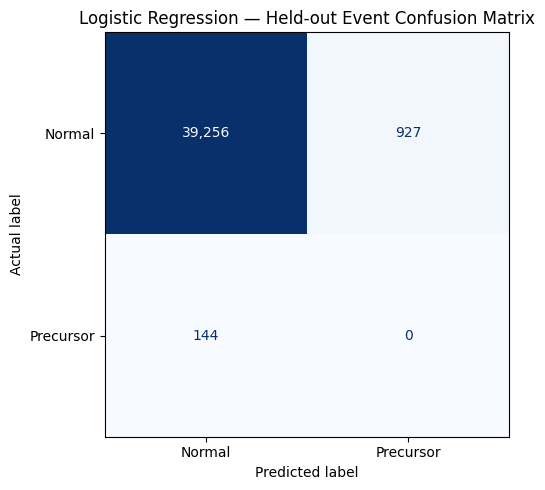

\nSVM (RBF)
TN=40,148 | FP=35 | FN=144 | TP=0


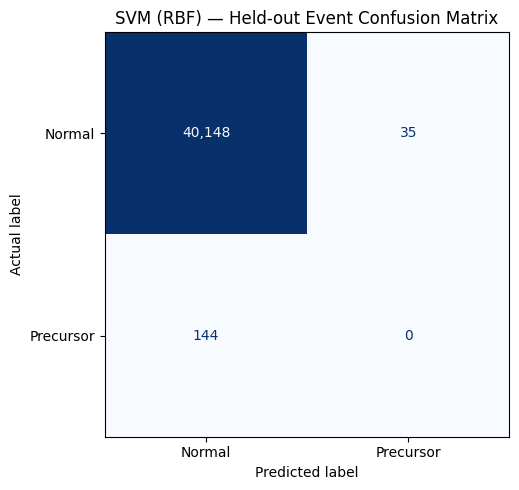

\nGaussian Naive Bayes
TN=40,183 | FP=0 | FN=144 | TP=0


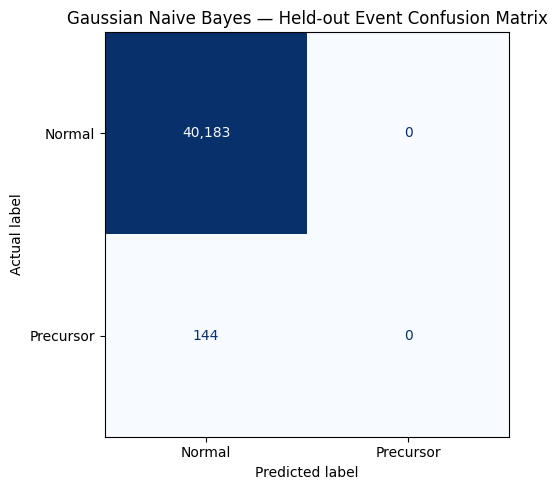

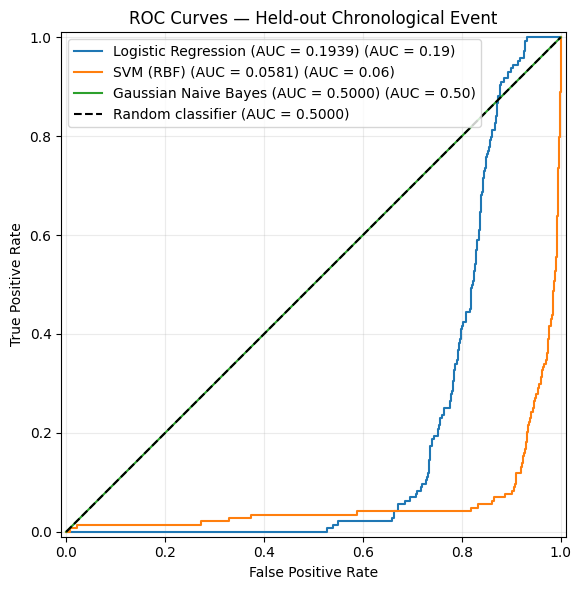

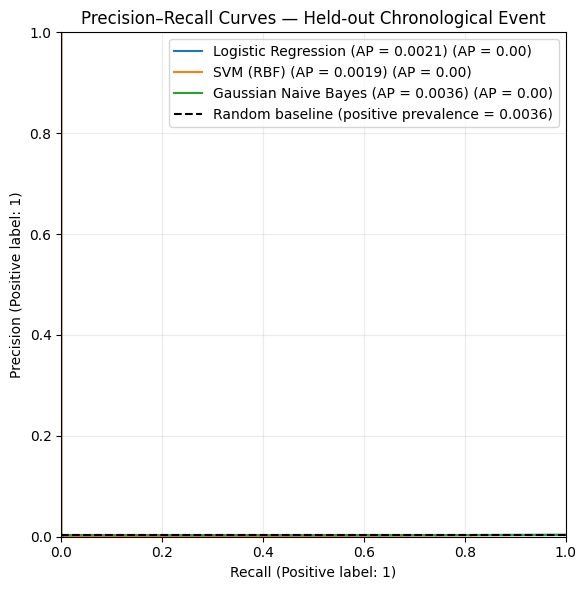

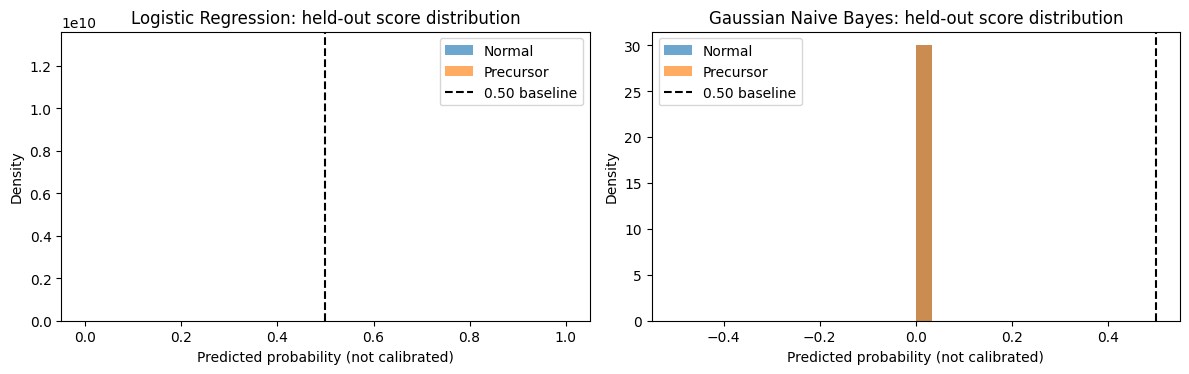

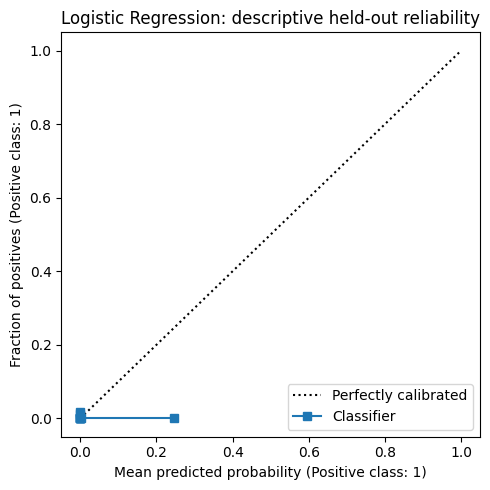

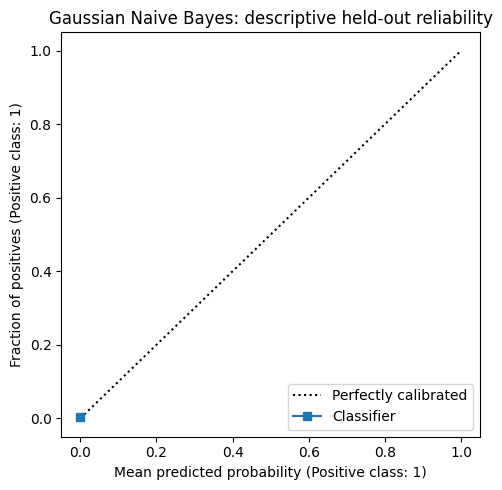

In [41]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    average_precision_score,
    roc_auc_score
)
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. CONFUSION MATRICES — MODEL-SPECIFIC BASELINE RULES
# --------------------------------------------------
# LR and GaussianNB: probability >= 0.50.
# SVM: native decision_function >= 0.
for name in fitted_models:
    cm = confusion_matrix(y_test, predictions[name], labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    print(f"\\n{name}")
    print(f"TN={tn:,} | FP={fp:,} | FN={fn:,} | TP={tp:,}")

    fig, ax = plt.subplots(figsize=(6, 5))
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Normal", "Precursor"]
    )
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format=",")
    ax.set_title(f"{name} — Held-out Event Confusion Matrix")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
    plt.tight_layout()
    plt.show()

# --------------------------------------------------
# 2. ROC CURVES — THRESHOLD-INDEPENDENT RANKING
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 6))
for name in fitted_models:
    score = model_scores[name]
    auc = roc_auc_score(y_test, score)
    RocCurveDisplay.from_predictions(
        y_test, score, name=f"{name} (AUC = {auc:.4f})", ax=ax
    )

ax.plot([0, 1], [0, 1], linestyle="--", color="black",
        label="Random classifier (AUC = 0.5000)")
ax.set_title("ROC Curves — Held-out Chronological Event")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.grid(alpha=0.25)
ax.legend(loc="best")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 3. PRECISION-RECALL CURVES — RARE POSITIVE CLASS
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 6))
for name in fitted_models:
    score = model_scores[name]
    ap = average_precision_score(y_test, score)
    PrecisionRecallDisplay.from_predictions(
        y_test, score, name=f"{name} (AP = {ap:.4f})", ax=ax
    )

baseline = y_test.mean()
ax.axhline(
    y=baseline, linestyle="--", color="black",
    label=f"Random baseline (positive prevalence = {baseline:.4f})"
)
ax.set_title("Precision–Recall Curves — Held-out Chronological Event")
ax.set_xlabel("Recall (Positive label: 1)")
ax.set_ylabel("Precision (Positive label: 1)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.grid(alpha=0.25)
ax.legend(loc="best")
plt.tight_layout()
plt.show()


# Held-out probability distributions; SVM margins are plotted separately.
probability_models = [n for n in fitted_models if n != "SVM (RBF)"]
if probability_models:
    fig, axes = plt.subplots(1, len(probability_models), figsize=(6 * len(probability_models), 4))
    if len(probability_models) == 1: axes = [axes]
    for ax, name in zip(axes, probability_models):
        score = model_scores[name]
        ax.hist(score[y_test.to_numpy() == 0], bins=30, alpha=.65, label="Normal", density=True)
        ax.hist(score[y_test.to_numpy() == 1], bins=30, alpha=.65, label="Precursor", density=True)
        ax.axvline(DECISION_THRESHOLD, color="black", linestyle="--", label="0.50 baseline")
        ax.set_title(f"{name}: held-out score distribution")
        ax.set_xlabel("Predicted probability (not calibrated)")
        ax.set_ylabel("Density")
        ax.legend()
    plt.tight_layout(); plt.show()

# Reliability diagrams are descriptive on this single held-out event only. They
# do not establish calibration and are not used to refit or adjust probabilities.
from sklearn.calibration import CalibrationDisplay
for name in probability_models:
    fig, ax = plt.subplots(figsize=(5, 5))
    CalibrationDisplay.from_predictions(y_test, model_scores[name], n_bins=10, strategy="quantile", ax=ax)
    ax.set_title(f"{name}: descriptive held-out reliability")
    plt.tight_layout(); plt.show()


### 9.5 Export per-observation risk scores

In [42]:
# Export held-out scores and predictions without mislabelling SVM margins as probabilities.
risk_output = pd.DataFrame(index=X_test.index)
risk_output["actual_precursor"] = y_test

for name in fitted_models:
    safe_name = (
        name.lower()
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
        .replace("-", "_")
    )
    score_label = "decision_score" if name == "SVM (RBF)" else "probability"
    risk_output[f"{safe_name}_{score_label}"] = model_scores[name]
    risk_output[f"{safe_name}_prediction"] = predictions[name]

display(risk_output.head())


,actual_precursor,logistic_regression_probability,logistic_regression_prediction,svm_rbf_decision_score,svm_rbf_prediction,gaussian_naive_bayes_probability,gaussian_naive_bayes_prediction
timestamp,,,,,,,
2019-03-26 20:40:00,1,2.536082e-14,0,-3.170852,0,0.0,0
2019-03-26 20:50:00,1,1.369678e-14,0,-3.153955,0,0.0,0
2019-03-26 21:00:00,1,1.705148e-14,0,-3.260001,0,0.0,0
2019-03-26 21:10:00,1,9.955895e-15,0,-3.353081,0,0.0,0
2019-03-26 21:20:00,1,3.550085e-15,0,-3.142718,0,0.0,0


### 9.6 Model metric comparison plot

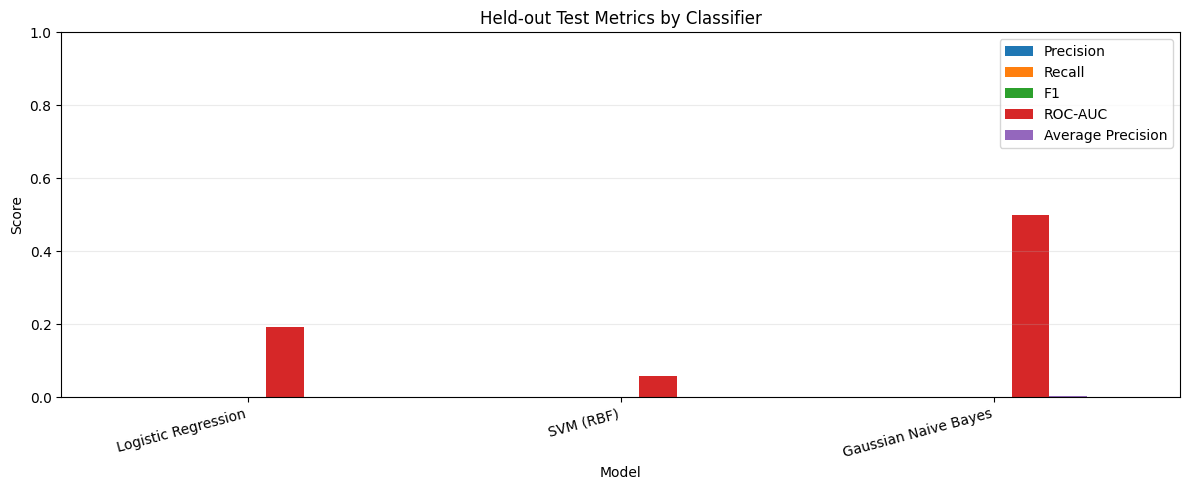

In [43]:

# Side-by-side comparison of key classification metrics.
metric_cols = [c for c in ["Precision", "Recall", "F1", "ROC-AUC", "Average Precision"]
               if c in results_df.columns]
if metric_cols:
    ax = results_df[metric_cols].plot(kind="bar", figsize=(12, 5), ylim=(0, 1))
    ax.set_title("Held-out Test Metrics by Classifier")
    ax.set_ylabel("Score")
    ax.set_xlabel("Model")
    ax.grid(axis="y", alpha=0.25)
    plt.xticks(rotation=15, ha="right")
    plt.tight_layout()
    plt.show()


### 9.7 Test-period risk score timeline

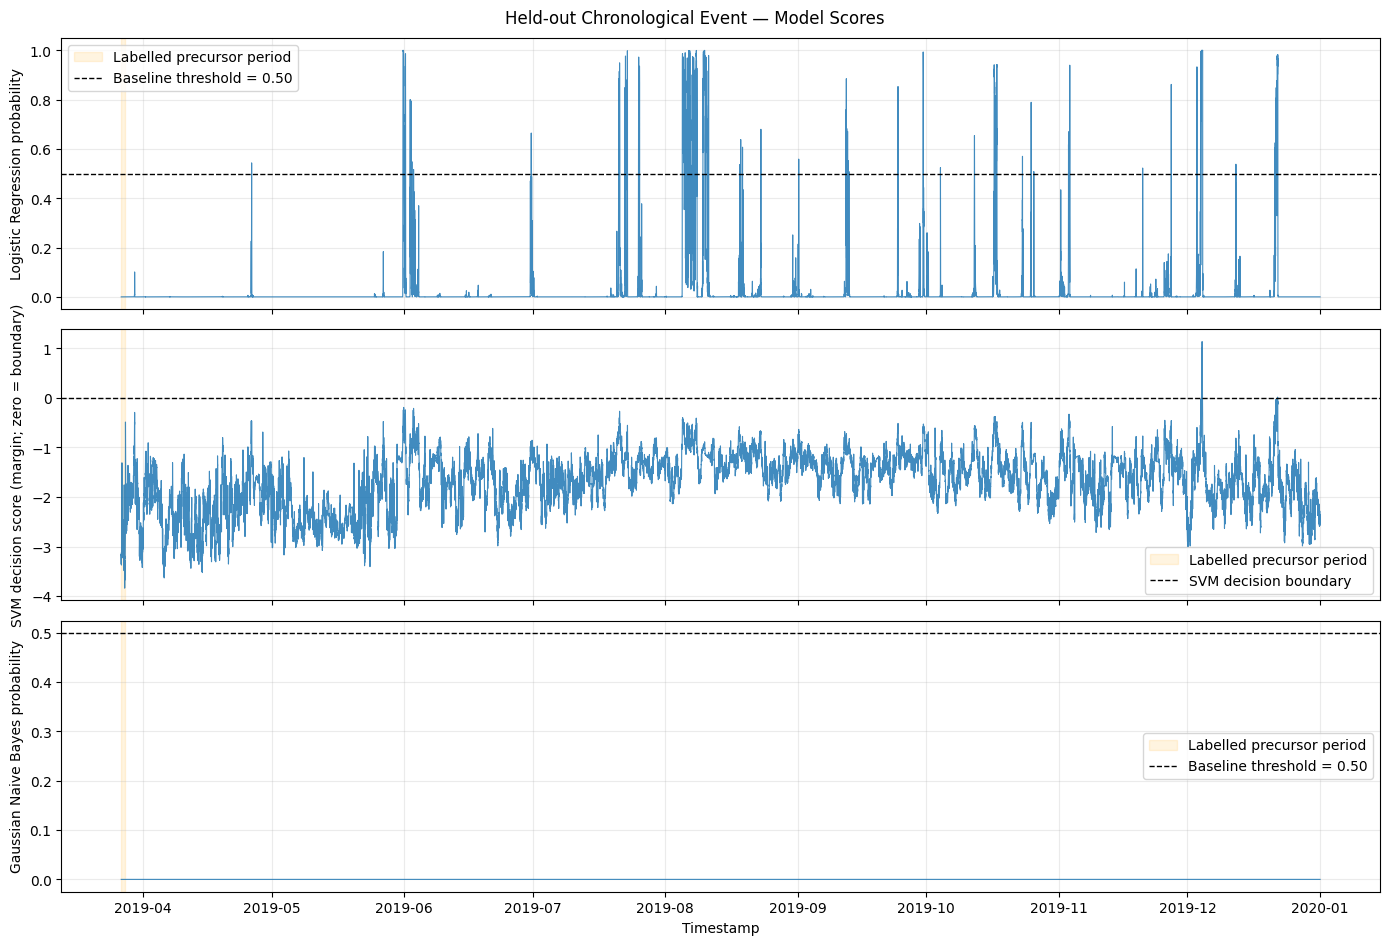

In [44]:
# Plot held-out model scores separately because SVM margins and probabilities
# are on different scales and must not share a probability axis.
score_specs = [
    ("logistic_regression_probability", "Logistic Regression probability"),
    ("svm_rbf_decision_score", "SVM decision score (margin; zero = boundary)"),
    ("gaussian_naive_bayes_probability", "Gaussian Naive Bayes probability")
]
available_specs = [(col, label) for col, label in score_specs if col in risk_output.columns]

if len(risk_output) and available_specs:
    fig, axes = plt.subplots(
        len(available_specs), 1,
        figsize=(14, 3.2 * len(available_specs)),
        sharex=True
    )
    if len(available_specs) == 1:
        axes = [axes]

    positive_mask = risk_output["actual_precursor"] == 1
    for ax, (col, label) in zip(axes, available_specs):
        ax.plot(risk_output.index, risk_output[col], linewidth=0.8, alpha=0.85)
        if positive_mask.any():
            ax.axvspan(
                risk_output.index[positive_mask].min(),
                risk_output.index[positive_mask].max(),
                color="orange", alpha=0.12,
                label="Labelled precursor period"
            )
        if col == "svm_rbf_decision_score":
            ax.axhline(0, color="black", linestyle="--", linewidth=1,
                       label="SVM decision boundary")
        else:
            ax.axhline(DECISION_THRESHOLD, color="black", linestyle="--",
                       linewidth=1, label=f"Baseline threshold = {DECISION_THRESHOLD:.2f}")
        ax.set_ylabel(label)
        ax.grid(alpha=0.25)
        ax.legend(loc="best")

    axes[-1].set_xlabel("Timestamp")
    fig.suptitle("Held-out Chronological Event — Model Scores")
    plt.tight_layout()
    plt.show()
else:
    print("No held-out model scores are available to plot.")


## 10. Export final project outputs

In [48]:
# Member 3 model packaging and exports. Use the existing project output folder.
# OUT_DIR is defined in cell 60 as /content/windguard_outputs.
import json
import sys
from pathlib import Path

from google.colab import drive
drive.mount('/content/drive')

output_dir = Path("/content/drive/MyDrive/member3_models")
output_dir.mkdir(parents=True, exist_ok=True)

MODEL_KEYS = {
    "logistic_regression": "Logistic Regression",
    "svm": "SVM (RBF)",
    "bayesian": "Gaussian Naive Bayes",
}
MODEL_FILES = {
    "logistic_regression": "logistic_regression.joblib",
    "svm": "svm.joblib",
    "bayesian": "bayesian.joblib",
}

# Save the fitted sklearn pipelines. Imputation/scaling are inside each pipeline.
for key, name in MODEL_KEYS.items():
    joblib.dump(fitted_models[name], output_dir / MODEL_FILES[key])

metadata = {
    "models": MODEL_FILES,
    "features": list(model_features),
    "target": "precursor",
    "positive_class": 1,
    "baseline_probability_threshold": float(DECISION_THRESHOLD),
    "svm_threshold": 0.0,
    "probability_calibration": "not fitted: only two independent failure events are available",
    "validation": "one training event and one untouched chronological test event",
    "score_semantics": {
        "logistic_regression": "uncalibrated_model_probability",
        "svm": "uncalibrated_decision_margin",
        "bayesian": "uncalibrated_model_probability",
    },
}
(output_dir / "model_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")

# Ship the reusable inference module and Streamlit page beside the saved models.
member3_predict_source = '"""Reusable inference for the WindGuard Member 3 fitted pipelines.\n\nModel files and metadata are read from /content/drive/MyDrive/member3_models\nby default in Colab, or from an explicit model_dir.\n"""\nfrom __future__ import annotations\nimport json\nimport os\nfrom functools import lru_cache\nfrom pathlib import Path\nfrom typing import Mapping\nimport joblib\nimport numpy as np\nimport pandas as pd\n\nDEFAULT_MODEL_DIR = Path(os.environ.get(\n    "WINDGUARD_MODEL_DIR", "/content/windguard_outputs/member3_models"\n))\nALIASES = {\n    "logistic regression": "logistic_regression",\n    "logistic_regression": "logistic_regression",\n    "svm": "svm", "svm (rbf)": "svm",\n    "bayesian": "bayesian", "gaussian naive bayes": "bayesian",\n    "bayesian classifier": "bayesian",\n}\n\ndef _normalise_input(input_data: pd.DataFrame | Mapping | list) -> pd.DataFrame:\n    if isinstance(input_data, pd.DataFrame):\n        frame = input_data.copy()\n    elif isinstance(input_data, Mapping):\n        frame = pd.DataFrame([input_data])\n    elif isinstance(input_data, list):\n        frame = pd.DataFrame(input_data)\n    else:\n        raise TypeError("input_data must be a pandas DataFrame, mapping, or list of mappings")\n    if frame.empty:\n        raise ValueError("input_data must contain at least one row")\n    if not frame.columns.is_unique:\n        raise ValueError("input_data contains duplicate column names")\n    return frame\n\n@lru_cache(maxsize=16)\ndef _load_bundle(model_dir_str: str):\n    model_dir = Path(model_dir_str).expanduser().resolve()\n    metadata_path = model_dir / "model_metadata.json"\n    if not metadata_path.is_file():\n        raise FileNotFoundError(f"Model metadata not found: {metadata_path}")\n    with metadata_path.open(encoding="utf-8") as stream:\n        metadata = json.load(stream)\n    required = {"models", "features", "baseline_probability_threshold", "svm_threshold"}\n    missing = required - set(metadata)\n    if missing:\n        raise ValueError(f"Model metadata is missing keys: {sorted(missing)}")\n    return model_dir, metadata\n\n@lru_cache(maxsize=16)\ndef _load_model(model_dir_str: str, filename: str):\n    path = Path(model_dir_str) / filename\n    if not path.is_file():\n        raise FileNotFoundError(f"Fitted model not found: {path}. Run the notebook\'s Member 3 export cell first.")\n    return joblib.load(path)\n\ndef predict(model_name, input_data, model_dir=DEFAULT_MODEL_DIR, threshold=None):\n    """Return a consistent DataFrame with label, probability/margin and score type.\n\n    The saved sklearn pipeline performs the original imputation and scaling.\n    Features are reordered from metadata; absent columns raise an error. SVM\n    outputs a signed decision margin and leaves risk_prob null. LR/GNB outputs\n    are uncalibrated model probabilities (not calibrated failure probabilities).\n    """\n    key = ALIASES.get(str(model_name).strip().lower())\n    if key is None:\n        raise ValueError("model_name must be Logistic Regression, SVM, or Bayesian classifier")\n    frame = _normalise_input(input_data)\n    model_dir = Path(model_dir).expanduser().resolve()\n    directory, metadata = _load_bundle(str(model_dir))\n    features = list(metadata["features"])\n    if not features or len(features) != len(set(features)):\n        raise ValueError("Saved feature metadata is empty or contains duplicate names")\n    missing = [name for name in features if name not in frame.columns]\n    if missing:\n        raise ValueError(f"Missing required model features: {missing}")\n    try:\n        X = frame.loc[:, features].apply(pd.to_numeric, errors="coerce")\n    except Exception as exc:\n        raise ValueError("Model input features must be numeric or missing") from exc\n    X = X.replace([np.inf, -np.inf], np.nan)\n    model_map = metadata["models"]\n    if key not in model_map:\n        raise ValueError(f"No saved model is registered for {key!r}")\n    model = _load_model(str(directory), str(model_map[key]))\n    result = pd.DataFrame(index=frame.index)\n    result["model_name"] = {"logistic_regression": "Logistic Regression",\n                            "svm": "SVM (RBF)", "bayesian": "Gaussian Naive Bayes"}[key]\n    result["predicted_label"] = 0\n    result["risk_prob"] = np.nan\n    result["decision_score"] = np.nan\n    if key == "svm":\n        scores = np.asarray(model.decision_function(X), dtype=float).reshape(-1)\n        result["decision_score"] = scores\n        result["predicted_label"] = (scores >= float(metadata["svm_threshold"])).astype(int)\n        result["score_type"] = "uncalibrated_decision_margin"\n    else:\n        probs = np.asarray(model.predict_proba(X), dtype=float)\n        classes = list(getattr(model, "classes_", []))\n        if probs.ndim != 2 or 1 not in classes:\n            raise ValueError("Saved probability model has no positive class (1)")\n        positive_index = classes.index(1)\n        risk = probs[:, positive_index]\n        cutoff = metadata["baseline_probability_threshold"] if threshold is None else float(threshold)\n        if not 0 <= cutoff <= 1:\n            raise ValueError("threshold must be between 0 and 1")\n        result["risk_prob"] = risk\n        result["predicted_label"] = (risk >= cutoff).astype(int)\n        result["score_type"] = "uncalibrated_model_probability"\n    return result\n'
member3_dashboard_source = '"""WindGuard Member 3 Turbine Risk page. Reads actual notebook prediction exports only.\nRun with: streamlit run member3_dashboard.py\n"""\nfrom pathlib import Path\nimport pandas as pd\nimport plotly.express as px\nimport plotly.graph_objects as go\nimport streamlit as st\n\ndef _prediction_path():\n    here = Path(__file__).resolve().parent\n    candidates = [here / "member3_models" / "member3_predictions.csv",\n                  here / "member3_predictions.csv",\n                  Path("/content/windguard_outputs/member3_models/member3_predictions.csv")]\n    return next((path for path in candidates if path.is_file()), candidates[-1])\n\nst.set_page_config(page_title="WindGuard | Turbine Risk", layout="wide")\nst.title("Turbine Risk")\nst.caption("Uses model-generated chronological predictions. LR/GaussianNB probabilities are uncalibrated; SVM values are signed decision margins.")\ncsv_path = _prediction_path()\nif not csv_path.is_file():\n    st.error(f"Prediction export not found: {csv_path}. Run the notebook\'s Member 3 export cell first.")\n    st.stop()\ntry:\n    data = pd.read_csv(csv_path, parse_dates=["timestamp"])\nexcept Exception as exc:\n    st.error(f"Could not read prediction export: {exc}")\n    st.stop()\nrequired = {"turbine_id", "timestamp", "regime", "risk_prob", "model_name",\n            "prediction_window", "predicted_label", "decision_score", "score_type"}\nmissing = sorted(required - set(data.columns))\nif missing:\n    st.error(f"Prediction export is missing required columns: {missing}")\n    st.stop()\nif data.empty:\n    st.warning("The prediction export contains no rows.")\n    st.stop()\n\nmodel_names = sorted(data["model_name"].dropna().unique().tolist())\nturbine_ids = sorted(data["turbine_id"].dropna().astype(str).unique().tolist())\nwindows = sorted(data["prediction_window"].dropna().astype(str).unique().tolist())\nif not model_names or not turbine_ids or not windows:\n    st.error("The prediction export must contain model names, turbine IDs, and prediction windows.")\n    st.stop()\na, b, c = st.columns(3)\nselected_model = a.selectbox("Model", model_names)\nselected_turbines = b.multiselect("Turbine(s)", turbine_ids, default=turbine_ids[:1])\nselected_window = c.selectbox("Prediction window", windows)\nselected = data[(data.model_name == selected_model) &\n                (data.turbine_id.astype(str).isin(selected_turbines)) &\n                (data.prediction_window.astype(str) == selected_window)].copy()\nselected = selected.sort_values("timestamp")\nif selected.empty:\n    st.info("No model-generated rows match the selected turbine and window.")\n    st.stop()\n\nst.subheader("Configurable risk display bands")\nst.caption("Default bands are illustrative display categories only; they are not scientifically validated alert thresholds. Adjust them for exploration; validate against more independent failure events before operational use.")\nx, y = st.columns(2)\nlow = x.slider("Low / Medium probability boundary", 0.0, 1.0, 0.10, 0.01)\nhigh = y.slider("Medium / High probability boundary", 0.0, 1.0, 0.30, 0.01)\nif low >= high:\n    st.warning("Set the Low/Medium boundary below the Medium/High boundary.")\n\nleft, right = st.columns([1, 2])\nlatest = selected.iloc[-1]\nif pd.notna(latest["risk_prob"]):\n    probability = float(latest["risk_prob"])\n    left.metric("Latest uncalibrated model probability", f"{probability:.1%}")\n    gauge = go.Figure(go.Indicator(mode="gauge+number", value=probability * 100,\n        number={"suffix": "%"}, title={"text": "Raw model probability (not calibrated)"},\n        gauge={"axis": {"range": [0, 100]}, "bar": {"color": "#276EF1"},\n               "steps": [{"range": [0, low * 100], "color": "#DDF2E1"},\n                         {"range": [low * 100, high * 100], "color": "#FFF0C2"},\n                         {"range": [high * 100, 100], "color": "#FADBD8"}]}))\n    gauge.update_layout(height=280, margin=dict(l=15, r=15, t=55, b=10))\n    left.plotly_chart(gauge, use_container_width=True)\n    left.caption("Gauge shows an uncalibrated model probability, not a validated failure probability.")\nelse:\n    left.metric("Latest SVM decision margin", f"{float(latest[\'decision_score\']):.4f}")\n    left.caption("SVM margin is not a probability; no probability gauge is shown for SVM.")\n\n# Configurable presentation bands. They are display settings, not validated\n# operational thresholds; a deployment threshold needs event-level validation.\nwith right:\n    st.subheader("Risk timeline")\n    if selected["risk_prob"].notna().any():\n        timeline_col = "risk_prob"\n        timeline_label = "Uncalibrated model probability"\n    else:\n        timeline_col = "decision_score"\n        timeline_label = "SVM decision margin (not probability)"\n    fig = px.line(selected, x="timestamp", y=timeline_col, color="turbine_id",\n                  hover_data=["regime", "predicted_label", "score_type"],\n                  labels={timeline_col: timeline_label}, title=timeline_label + " over time")\n    st.plotly_chart(fig, use_container_width=True)\n\nif low < high:\n    comparison = data[(data.turbine_id.astype(str).isin(selected_turbines)) &\n                      (data.prediction_window.astype(str) == selected_window)].copy()\n    comparison["risk_category"] = "SVM margin (not probability)"\n    probability_rows = comparison["risk_prob"].notna()\n    comparison.loc[probability_rows, "risk_category"] = pd.cut(\n        comparison.loc[probability_rows, "risk_prob"],\n        bins=[-0.001, low, high, 1.001], labels=["Low", "Medium", "High"]\n    ).astype("string")\n    st.subheader("Three-model comparison")\n    st.caption("Scores are not directly comparable across probability and margin scales. SVM margins remain separate from probability estimates.")\n    latest_by_model = (comparison.sort_values("timestamp")\n                       .groupby(["turbine_id", "model_name", "prediction_window"], as_index=False)\n                       .tail(1).sort_values(["turbine_id", "model_name"]))\n    st.dataframe(latest_by_model[["turbine_id", "timestamp", "regime", "model_name",\n        "prediction_window", "actual_label", "predicted_label", "risk_prob",\n        "decision_score", "score_type", "risk_category"]], use_container_width=True, hide_index=True)\n    st.subheader("Prediction results")\n    st.dataframe(comparison.sort_values(["timestamp", "model_name"]),\n                 use_container_width=True, hide_index=True)\n'
if str(output_dir) not in sys.path:
    sys.path.insert(0, str(output_dir))

# Importing the module proves that inference is based on disk-saved models and
# metadata, independently of the current notebook's fitted_models dictionary.
import importlib.util
_predict_spec = importlib.util.spec_from_file_location("windguard_member3_predict", output_dir / "member3_predict.py")
_predict_module = importlib.util.module_from_spec(_predict_spec)
_predict_spec.loader.exec_module(_predict_module)
predict = _predict_module.predict

# Export model-generated rows in the shared data contract. A missing regime stays null.
if "Regime" in cluster_df.columns:
    regime_series = cluster_df["Regime"].reindex(X_test.index)
else:
    regime_series = pd.Series(np.nan, index=X_test.index)
prediction_blocks = []
for key, model_name in MODEL_KEYS.items():
    pred = predict(X_test, key, model_dir=output_dir)
    block = pd.DataFrame(index=X_test.index)
    block["turbine_id"] = "T1"  # source SCADA file is the actual turbine 1 record
    block["timestamp"] = X_test.index
    block["regime"] = regime_series.to_numpy()
    block["risk_prob"] = pred["risk_prob"].to_numpy()
    block["model_name"] = model_name
    block["prediction_window"] = "24h precursor label window"
    block["actual_label"] = y_test.to_numpy()
    block["predicted_label"] = pred["predicted_label"].to_numpy()
    block["decision_score"] = pred["decision_score"].to_numpy()
    block["score_type"] = pred["score_type"].to_numpy()
    prediction_blocks.append(block)
predictions_long = pd.concat(prediction_blocks).reset_index(drop=True)
contract_columns = ["turbine_id", "timestamp", "regime", "risk_prob"]
assert set(contract_columns).issubset(predictions_long.columns)
predictions_long.to_csv(output_dir / "member3_predictions.csv", index=False)
results_df.to_csv(output_dir / "model_comparison.csv")
risk_output.to_csv(output_dir / "test_risk_predictions_wide.csv", index_label="timestamp")
print("Member 3 models, metadata, inference module, dashboard, and predictions saved to:", output_dir)
print("Generated files:", sorted(path.name for path in output_dir.iterdir() if path.is_file()))
print("Prediction rows:", len(predictions_long), "| missing source regimes:", int(predictions_long["regime"].isna().sum()))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Member 3 models, metadata, inference module, dashboard, and predictions saved to: /content/drive/MyDrive/member3_models
Generated files: ['T1_engineered_features.csv', 'bayesian.joblib', 'logistic_regression.joblib', 'member3_dashboard.py', 'member3_predict.py', 'member3_predictions.csv', 'model_comparison.csv', 'model_metadata.json', 'svm.joblib', 'test_risk_predictions_wide.csv']
Prediction rows: 120981 | missing source regimes: 120981


### 12. Push outputs to GitHub
Configure your repository and GitHub Personal Access Token (PAT) to upload the model results and datasets.

In [49]:
# GitHub publishing is intentionally disabled for the Colab verification run.
# The original cell performed `git push --force` to the configured repository.
# Review the generated files first; publish manually only if you explicitly intend to update the remote repository.
print('GitHub push skipped. Review /content/windguard_outputs before publishing manually.')


GitHub push skipped. Review /content/windguard_outputs before publishing manually.


## 11. Member 3 — Classification and Bayesian results

### Objective and implementation

The target is the existing `precursor` label: SCADA observations within the 24-hour window before a labelled hydraulic failure. Active fault rows are excluded. Logistic Regression models regularised linear log-odds; RBF SVM uses a nonlinear maximum-margin boundary; Gaussian Naive Bayes applies Bayes’ rule with conditionally independent Gaussian features. Existing Member 2 feature engineering is reused. Median imputation and standardisation are fitted inside each sklearn pipeline on training rows only. Logistic Regression and SVM retain class weighting; Gaussian Naive Bayes is the retained unweighted probabilistic baseline.

### Validation, imbalance, and why tuning/SMOTE/calibration are withheld

Only two independent hydraulic failure events are labelled: Event 1 is the only positive event available for training; Event 2 is kept as the untouched chronological test. There is no independent event for selecting hyperparameters, a threshold, or a calibrator. Random row-level CV would split highly correlated samples from the same event across folds, and using Event 2 for model selection would contaminate the sole held-out evaluation. SMOTE cannot create additional independent failure events; fold-local SMOTE would still learn from essentially one event and cannot be validated for event-level generalisation. Therefore no SMOTE, random CV, event-level tuning, test-selected threshold, or calibrated probabilities are used. Existing baseline hyperparameters are retained.

### Existing held-out results (not altered)

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC | Average Precision | Brier* |
|---|---:|---:|---:|---:|---:|---:|---:|
| Logistic Regression | 0.97344 | 0.00000 | 0.00000 | 0.00000 | 0.19390 | 0.00214 | 0.02028 |
| RBF SVM | 0.99556 | 0.00000 | 0.00000 | 0.00000 | 0.05809 | 0.00187 | N/A |
| Gaussian Naive Bayes | 0.99643 | 0.00000 | 0.00000 | 0.00000 | 0.50000 | 0.00357 | 0.00357 |

*Brier scores are descriptive for uncalibrated probabilities only; SVM emits a signed decision margin and has no probability/Brier score. Test support is 40,183 normal and 144 precursor observations. Confusion counts: LR TN=39,256 FP=927 FN=144 TP=0; SVM TN=40,148 FP=35 FN=144 TP=0; GNB TN=40,183 FP=0 FN=144 TP=0. All three default rules miss every labelled precursor row. High accuracy is driven by class imbalance and does not represent successful failure detection. No metrics are improved or fabricated here.

### Packaging, data contract, dashboard, and remaining validation

The notebook saves model pipelines, metadata, a reusable disk-loading `predict()` module, the Streamlit page, metrics, and actual prediction rows under `/content/windguard_outputs/member3_models`. Exports include `turbine_id`, `timestamp`, `regime`, and `risk_prob`; SVM `risk_prob` stays null while its `decision_score` is separate. Regime is joined from Member 1’s existing K-Means output when available and remains null when unavailable. The dashboard reads the generated CSV, provides model/turbine/window filters, a risk gauge only for probability models, a risk timeline, model comparison, and a results table. Display bands are configurable and labelled illustrative, not validated operational thresholds.

Execution depends on the intended Colab environment. The local authoring environment may lack notebook/dashboard dependencies; do not treat saved code as executed results.


In [50]:

import requests
import base64
import getpass
import os

# Repository details
REPO_OWNER = "Mehak1805"
REPO_NAME = "WindGuard-Wind-Turbine-Failure-Precursor-Detection"
BRANCH = "main"
FILE_PATH = "WindGuard_Aditya.ipynb"

# Actual notebook location in Google Drive
LOCAL_FILE = "/content/drive/MyDrive/Colab Notebooks/WindGuard_Aditya.ipynb"

# Verify notebook exists
if not os.path.exists(LOCAL_FILE):
    raise FileNotFoundError(f"Notebook not found at {LOCAL_FILE}")

print("Notebook found successfully!")

# Enter GitHub Classic Personal Access Token
GITHUB_TOKEN = getpass.getpass("Enter your GitHub Personal Access Token: ")

# Read and encode notebook
with open(LOCAL_FILE, "rb") as f:
    file_content = base64.b64encode(f.read()).decode("utf-8")

# GitHub API
api_url = (
    f"https://api.github.com/repos/"
    f"{REPO_OWNER}/{REPO_NAME}/contents/{FILE_PATH}"
)

headers = {
    "Authorization": f"Bearer {GITHUB_TOKEN}",
    "Accept": "application/vnd.github+json",
    "X-GitHub-Api-Version": "2022-11-28"
}

# Check whether file already exists on main
response = requests.get(
    api_url,
    headers=headers,
    params={"ref": BRANCH}
)

payload = {
    "message": "Update WindGuard_Aditya.ipynb",
    "content": file_content,
    "branch": BRANCH
}

if response.status_code == 200:
    payload["sha"] = response.json()["sha"]
    print("Existing notebook found. Updating it...")
elif response.status_code == 404:
    print("Notebook not found in repository. Creating it...")
else:
    raise Exception(
        f"GitHub error: {response.status_code}\n{response.text}"
    )

# Push notebook to GitHub
push_response = requests.put(
    api_url,
    headers=headers,
    json=payload
)

if push_response.status_code in [200, 201]:
    print("\nSUCCESS! Notebook pushed to GitHub.")
    print("Branch:", BRANCH)
    print("File:", FILE_PATH)
    print("Commit URL:", push_response.json()["commit"]["html_url"])
else:
    print("\nUPLOAD FAILED")
    print(push_response.status_code)
    print(push_response.text)


FileNotFoundError: Notebook not found at /content/WindGuard_Aditya.ipynb